# TRMM trackwise dataset and baseline results

This notebook covers the **TRMM benchmark**: should the Precipitation Radar (PR) be switched on this minute, decided only from what the passive Visible and Infrared Scanner (VIRS) and the orbit geometry can see?

It has two parts:

1. **The dataset**: how it was built, integrity checks, and what the weather in it looks like.
2. **The baseline results** (experiments E1–E11): how well simple, fixed policies can decide
   when to switch the radar on under a power budget. These are the numbers any RL agent has
   to beat.

Nothing here downloads data or re-runs the extraction. The notebook reads
`data/TRMM_trackwise_decisions.parquet` and the CSVs in `results/`, and takes the orbit and time-window
settings directly from `extract_trackwise.py` and `trackwise_missions.py`, so it always matches
the pipeline that produced the data.

**Rebuild everything** (from the repository root):

```
python3 extract_trackwise.py --mission trmm                                # weather along the orbit, 59 blocks
python3 task_outputs/fetch_g5nr_constants.py                                   # once: land/water grid
python3 task_outputs/enrich_trackwise.py --mission trmm <extraction cache> # -> data/
python  -m baselines.run_baselines --mission trmm --mlp                    # -> results/
```

## 1. How the dataset was built

| step | what happens |
|---|---|
| **orbit** | TRMM's position every second, from a set of real TLEs (NORAD 25063) covering 2005-06-01 → 2006-02-01: a 35° precessing orbit at ~400 km that samples every local time. The TLE closest in time is used for each moment. |
| **weather** | GEOS-5 Nature Run (G5NR), a 7 km global simulation, sampled every 30 minutes at 0.0625°. |
| **time alignment** | TRMM flew during G5NR's own period, so the orbit and the weather share the **calendar date and UTC time** (orbit 2005-06-01 15:00 = G5NR 2005-06-01 15:00, step 803). |
| **decision** | One row per minute: should the PR be on? 30 decisions share each 30-minute weather snapshot. |
| **passive features** | VIRS-like cloud diagnostics averaged over the 833 km VIRS swath under the satellite during that minute (cloud fraction, cloud-top temperature, optical depth, and outgoing longwave as a stand-in for the VIRS thermal-infrared window; TRMM had no working broadband radiometer in 2005). |
| **targets** | Total and convective precipitation: the maximum over the 247 km **PR swath** (what the PR measures, the label), its mean over the PR swath (the weight for mass-capture), and for comparison the maximum over the **VIRS swath** and along the **nadir** line. |
| **enrichment** | Land/water fraction under the track, cyclic longitude, solar hour, validity flags. No forward-view feature: VIRS is a cross-track scanner. |

The extraction refuses to save a block unless every request succeeded, and any footprint without a grid cell inside it stops the run. The range check in §2 verifies that no physically impossible values reached the dataset.

In [1]:
import hashlib
import json
import re
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Markdown, display

MISSION_NAME = "trmm"
ROOT = Path.cwd().resolve().parents[1]                 # notebook lives in missions/<mission>/
assert (ROOT / "extract_trackwise.py").exists(), f"run this notebook from missions/{MISSION_NAME}/ ({ROOT})"
sys.path.insert(0, str(ROOT))
import extract_trackwise as X                          # the pipeline's own settings
import trackwise_missions as TM

M = TM.get(MISSION_NAME)
orb = X.orbit(MISSION_NAME)
DATA = M.data_path
RES = M.folder / "results"
MM = 3600.0                                            # kg m-2 s-1 -> mm/hr
RAIN = 1.0 / MM                                        # benchmark label: >= 1 mm/hr
GEOMS = M.geometries                                   # label geometries, the radar's own first
LABEL = f"prectot_{GEOMS[0]}"                        # the benchmark label column
CONV = f"preccon_{GEOMS[0]}"
WHERE = {"nadir": "at nadir", "radar": f"in the {M.radar_name} swath", "swath": "in the passive swath"}

pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 30)
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})

n_tle, ep0, ep1, gap = orb.check_tle_coverage(M.startdate + X.N_FIELDS * X.G5_STEP)
print(f"mission    : {M.title} (NORAD {M.norad}), passive {M.passive.name} {M.passive.swath_m / 1e3:.0f} km, "
      f"radar {M.radar_name} " + (f"{M.radar.swath_m / 1e3:.0f} km swath" if M.radar else "nadir only"))
print(f"orbit      : {Path(M.tle_file).relative_to(ROOT)}  ({n_tle} TLEs, "
      f"{ep0:%Y-%m-%d} .. {ep1:%Y-%m-%d}, largest gap {gap})")
print(f"orbit start: {M.startdate:%Y-%m-%d %H:%M} UTC  <->  G5NR step {X.FIELD_START}")
print(f"window     : {X.N_FIELDS:,} weather steps x {X.PER_FIELD} decisions = "
      f"{X.N_FIELDS * X.PER_FIELD:,} one-minute decisions "
      f"({X.N_FIELDS * X.G5_STEP.total_seconds() / 86400:.0f} days)")

mission    : TRMM (NORAD 25063), passive VIRS 833 km, radar PR 247 km swath
orbit      : missions/trmm/tle/sat000025063.txt  (380 TLEs, 2005-05-25 .. 2006-02-08, largest gap 3 days, 0:23:19.107177)
orbit start: 2005-06-01 15:00 UTC  <->  G5NR step 803
window     : 11,760 weather steps x 30 decisions = 352,800 one-minute decisions (245 days)


## 2. Load the dataset and check it

These checks fail loudly if the file does not match the pipeline: every column in registry
order, every decision present exactly once, each row tied to the right weather step, the hash
matching the enrichment report and the baseline run, and every weather value within physical
limits.

In [2]:
rows = pd.read_parquet(DATA)
report = json.loads((DATA.parent / "enrich_report.json").read_text())
meta = json.loads((RES / "run_meta.json").read_text())
registry = re.findall(r"^  - name: (\S+)", M.registry.read_text(), flags=re.M)

N = X.N_FIELDS * X.PER_FIELD
assert list(rows.columns) == registry, "columns differ from the mission's column registry"
assert len(rows) == N, len(rows)
assert np.array_equal(rows.decision.to_numpy(), np.arange(N)), "decisions are not 0..N-1"
assert (rows.g5_step == X.FIELD_START + rows.decision // X.PER_FIELD).all()
assert report["sha256"] == meta["data_sha256"], "results were computed on a different dataset"
assert hashlib.sha256(DATA.read_bytes()).hexdigest() == report["sha256"], "parquet changed since enrichment"

# physical limits by variable; G5NR's wettest cell is ~400 mm/hr (TRMM, Typhoon Talim's eyewall,
# 2005-08-30), well under 0.2 kg m-2 s-1 (720 mm/hr)
RANGES = [("cld", "_mean", (0, 1)), ("tau", "", (0, 1e3)), ("cldtmp", "", (150, 330)),
          ("lwtup", "", (50, 450)), ("prec", "", (0, 0.2)), ("iwp", "", (0, 20)), ("lwp", "", (0, 20))]
def limits(c):
    hit = [r for p, s, r in RANGES if c.startswith(p) and c.endswith(s)]
    return hit[-1] if hit else None
LIMITS = {c: limits(c) for c in rows.columns if limits(c) and not c.endswith("_valid")}
audit = pd.DataFrame([{"column": c, "min": rows[c].min(), "max": rows[c].max(),
                       "NaN": int(rows[c].isna().sum()),
                       "out of range": int((rows[c].notna() & ~rows[c].between(lo, hi)).sum())}
                      for c, (lo, hi) in LIMITS.items()])
assert audit["out of range"].sum() == 0
display(audit.set_index("column"))

print(f"{len(rows):,} decisions x {rows.shape[1]} columns, sha256 {report['sha256'][:16]}...")
print(f"time: {rows.time.min():%Y-%m-%d %H:%M} -> {rows.time.max():%Y-%m-%d %H:%M} UTC (orbit clock)")
print(f"locations replaced by the nadir point (poles / dateline): {report['locations_replaced_by_nadir']:,}")
nan_tmp = rows.cldtmp_mean.isna()
print(f"cldtmp_mean NaN: {int(nan_tmp.sum()):,} (G5NR reports no cloud top anywhere in the swath; "
      f"median optical depth there {rows.loc[nan_tmp, 'tautot_mean'].median():.2f}, "
      f"{int((rows.loc[nan_tmp, LABEL] >= RAIN).sum())} rainy)")
if "lwtup_fore" in rows:
    print(f"lwtup_fore NaN: {report['lwtup_fore_nan']:,} (one per weather step: the last minute "
          "before the snapshot changes)")

,min,max,NaN,out of range
column,,,,
tautot_mean,0.000000,181.131638,0,0
cldtot_mean,0.000000,0.999710,0,0
cldtmp_mean,195.146255,302.546326,6598,0
lwtup_mean,121.939339,370.861359,0,0
tautot_max,0.000000,439.000000,0,0
prectot_radar,0.000000,0.111694,0,0
prectot_radar_mean,0.000000,0.002869,0,0
prectot_swath,0.000000,0.111694,0,0
prectot_nadir,0.000000,0.072388,0,0


352,800 decisions x 35 columns, sha256 fab9c8c7ebbd5fa7...
time: 2005-06-01 15:00 -> 2006-02-01 14:59 UTC (orbit clock)
locations replaced by the nadir point (poles / dateline): 6,397
cldtmp_mean NaN: 6,598 (G5NR reports no cloud top anywhere in the swath; median optical depth there 0.00, 0 rainy)


## 3. How often does it rain?

The benchmark label is **"precipitation ≥ 1 mm/hr anywhere in the PR swath"**, i.e. rain the scanning PR would measure. The swath column counts rain anywhere in the 833 km VIRS swath, most of which lies outside the PR's 247 km; the nadir column shows what a nadir-only radar (like EarthCARE's CPR) would see on the same track.

,prectot_radar (%),prectot_swath (%),prectot_nadir (%),preccon_radar (%),preccon_swath (%),preccon_nadir (%)
>= 0.1 mm/hr,75.1,87.3,51.1,41.9,56.4,26.3
>= 0.5 mm/hr,53.2,73.5,22.9,19.9,33.8,5.4
>= 1 mm/hr,41.6,63.9,14.9,11.6,23.4,2.0
>= 5 mm/hr,21.7,40.1,5.7,4.5,11.0,0.4
>= 10 mm/hr,15.7,31.0,3.4,2.4,6.6,0.2


At the 1 mm/hr label, 41.6% of minutes have rain in the PR swath and 63.9% somewhere in the passive swath: the swath label would credit the radar with 1.5x more rain than it can measure.


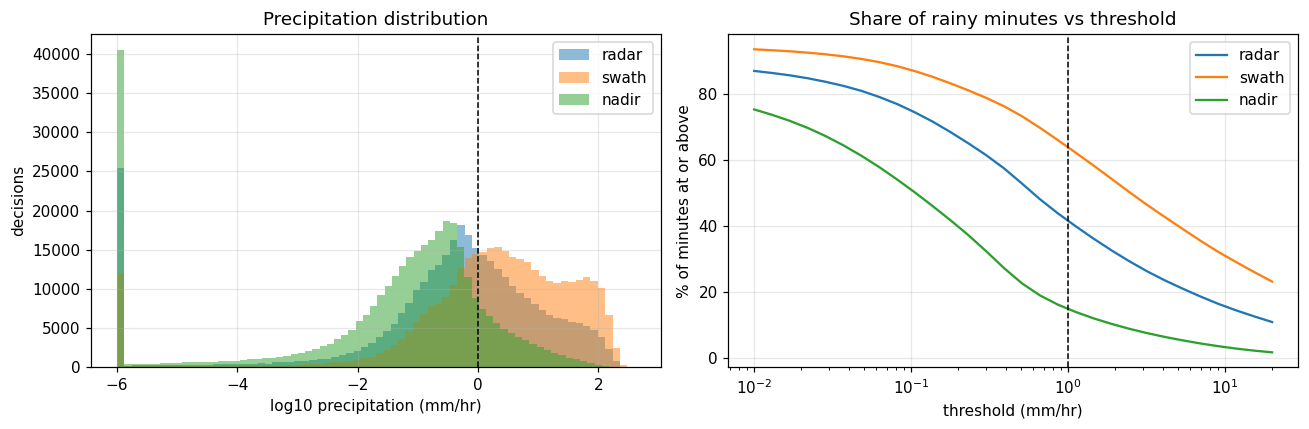

In [3]:
TARGETS = [f"{v}_{g}" for v in ("prectot", "preccon") for g in GEOMS]
THRESH = [0.1, 0.5, 1, 5, 10]
balance = pd.DataFrame({c: [100 * (rows[c] >= t / MM).mean() for t in THRESH] for c in TARGETS},
                       index=[f">= {t:g} mm/hr" for t in THRESH]).round(1)
display(balance.rename(columns=lambda c: c + " (%)"))
lab, sw = balance.loc[">= 1 mm/hr", LABEL], balance.loc[">= 1 mm/hr", "prectot_swath"]
print(f"At the 1 mm/hr label, {lab:.1f}% of minutes have rain {WHERE[GEOMS[0]]} and "
      f"{sw:.1f}% somewhere in the passive swath: the swath label would credit the radar with "
      f"{sw / lab:.1f}x more rain than it can measure.")

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
for g in GEOMS:
    c = f"prectot_{g}"
    v = rows[c].clip(lower=1e-6 / MM) * MM
    ax[0].hist(np.log10(v), bins=70, alpha=.5, label=g)
    th = np.logspace(-2, 1.3, 30)
    ax[1].plot(th, [100 * (rows[c] >= t / MM).mean() for t in th], label=g)
ax[0].axvline(0, color="k", ls="--", lw=1)
ax[0].set(xlabel="log10 precipitation (mm/hr)", ylabel="decisions", title="Precipitation distribution")
ax[1].axvline(1, color="k", ls="--", lw=1)
ax[1].set(xscale="log", xlabel="threshold (mm/hr)", ylabel="% of minutes at or above",
          title="Share of rainy minutes vs threshold")
for a in ax: a.legend()
plt.tight_layout(); plt.show()

## 4. Where and when it rains along the orbit

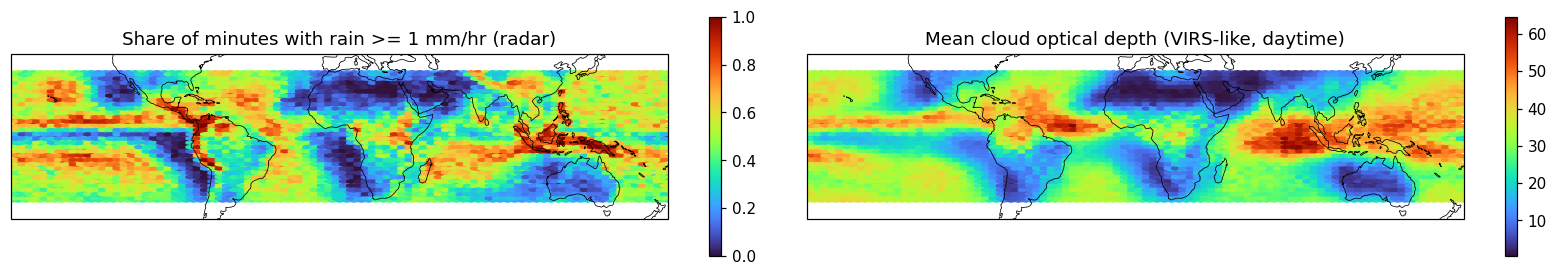

In [4]:
import cartopy.crs as ccrs

rows["rain"] = rows[LABEL] >= RAIN
lat_lim = min(90, 5 * np.ceil(rows.lat.abs().max() / 5) + 5)
fig, ax = plt.subplots(1, 2, figsize=(15, 4.2 if lat_lim == 90 else 3.2),
                       subplot_kw={"projection": ccrs.PlateCarree()})
for a, (col, title, red) in zip(ax, [
        ("rain", f"Share of minutes with rain >= 1 mm/hr ({GEOMS[0]})", np.mean),
        ("tautot_mean", f"Mean cloud optical depth ({M.passive.name}-like, daytime)", np.nanmean)]):
    d = rows if col == "rain" else rows[rows.tautot_mean > 0]
    hb = a.hexbin(d.lon, d.lat, C=d[col].astype(float), gridsize=(90, 30), cmap="turbo",
                  reduce_C_function=red, mincnt=20, transform=ccrs.PlateCarree())
    a.coastlines(linewidth=0.5); a.set_extent([-180, 180, -lat_lim, lat_lim], crs=ccrs.PlateCarree())
    a.set_title(title)
    plt.colorbar(hb, ax=a, shrink=0.75)
plt.tight_layout(); plt.show()

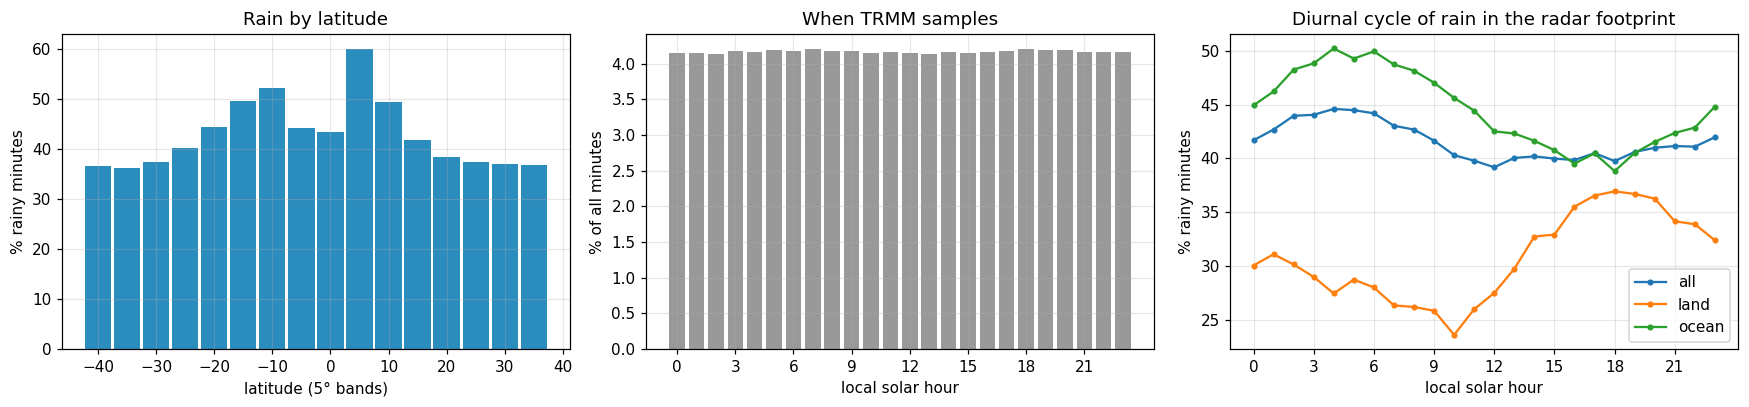

Precessing orbit: every local hour gets 4.1-4.2% of the minutes, at mean |lat| 21-22 deg, so time of day and latitude are not tied together and the diurnal cycle of rain is visible directly.


In [5]:
fig, ax = plt.subplots(1, 3, figsize=(16, 3.8))
lat = rows.groupby(rows.lat // 5 * 5).rain.mean() * 100
ax[0].bar(lat.index, lat.values, width=4.5, color="#2b8cbe")
ax[0].set(xlabel="latitude (5° bands)", ylabel="% rainy minutes", title="Rain by latitude")
sh = rows.assign(alat=rows.lat.abs()).groupby(rows.solar_hour.round().mod(24)).agg(
    n=("rain", "size"), rain=("rain", "mean"), alat=("alat", "mean"))
ax[1].bar(sh.index, 100 * sh.n / len(rows), color="0.6")
ax[1].set(xlabel="local solar hour", ylabel="% of all minutes", xticks=range(0, 24, 3),
          title=f"When {M.title} samples")
land = rows.land_frac_nadir > 0.95
for name, sel in [("all", slice(None)), ("land", land), ("ocean", rows.ocean_frac_nadir > 0.95)]:
    d = rows[sel]
    ax[2].plot(*zip(*d.groupby(d.solar_hour.round().mod(24)).rain.mean().mul(100).items()),
               marker=".", label=name)
ax[2].set(xlabel="local solar hour", ylabel="% rainy minutes", xticks=range(0, 24, 3),
          title="Diurnal cycle of rain in the radar footprint")
ax[2].legend()
plt.tight_layout(); plt.show()
print(f"Precessing orbit: every local hour gets {100 * sh.n.min() / len(rows):.1f}-"
      f"{100 * sh.n.max() / len(rows):.1f}% of the minutes, at mean |lat| "
      f"{sh.alat.min():.0f}-{sh.alat.max():.0f} deg, so time of day and latitude are not tied together "
      "and the diurnal cycle of rain is visible directly.")

## 5. Dataset structure checks

* **Land/water** under the nadir track, averaged over the minute's 60 one-second points.
* **Cyclic longitude**: `sin_lon`/`cos_lon` put −180° and +180° next to each other.
* **Persistence**: how quickly rain and clouds change from one minute to the next. This
  matters for an RL agent: if consecutive minutes were near-identical, "do what you did
  last minute" would be a strong policy.

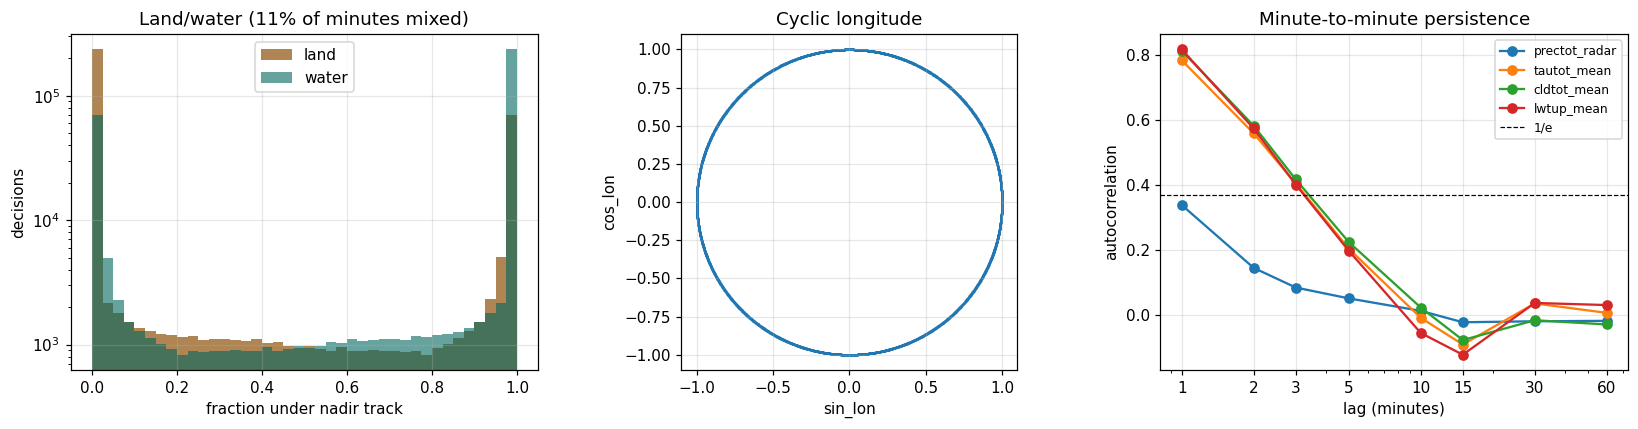

lag-1 autocorrelation: prectot_radar 0.34, tautot_mean 0.78, cldtot_mean 0.81, lwtup_mean 0.82
The satellite moves ~450 km per minute along track.


In [6]:
fig, ax = plt.subplots(1, 3, figsize=(15, 4))
ax[0].hist(rows.land_frac_nadir, bins=40, alpha=.7, color="#8c510a", label="land")
ax[0].hist(rows.ocean_frac_nadir, bins=40, alpha=.6, color="#01665e", label="water")
ax[0].set(xlabel="fraction under nadir track", ylabel="decisions", yscale="log",
          title=f"Land/water ({100 * report['mixed_surface_share']:.0f}% of minutes mixed)")
ax[0].legend()

ax[1].scatter(rows.sin_lon.iloc[::25], rows.cos_lon.iloc[::25], s=.4, alpha=.2)
ax[1].set(aspect="equal", xlabel="sin_lon", ylabel="cos_lon", title="Cyclic longitude")

lags = [1, 2, 3, 5, 10, 15, 30, 60]
PERSIST = [LABEL, "tautot_mean", "cldtot_mean", "lwtup_mean"]
for c in PERSIST:
    ax[2].plot(lags, [rows[c].autocorr(k) for k in lags], marker="o", label=c)
ax[2].axhline(np.exp(-1), color="k", ls="--", lw=.8, label="1/e")
ax[2].set(xscale="log", xticks=lags, xlabel="lag (minutes)", ylabel="autocorrelation",
          title="Minute-to-minute persistence")
ax[2].get_xaxis().set_major_formatter(plt.ScalarFormatter())
ax[2].legend(fontsize=8)
plt.tight_layout(); plt.show()
print("lag-1 autocorrelation: " + ", ".join(f"{c} {rows[c].autocorr(1):.2f}" for c in PERSIST))
print("The satellite moves ~450 km per minute along track.")

# Primary evaluation: seasonal robustness

Seasonal leave-one-month-out asks whether the policy remains reliable across the sampled weather
regimes. The **Chronological future-season stress test** below separately asks how preparation on
June–September and October transfers into November–January, including the existing February tail.
The latter is not evidence of general all-season performance. LOMO trains on the other seven
G5NR weather months, which may include months after the held-out month. All preprocessing and
thresholds use training-side data. Quantile gates have nominal budgets, not guaranteed test duty.

This section reads generated results and verifies fold definitions with `baselines.core`; it has
no independent split logic and performs no model fitting, extraction or export. Provenance checks
run in the baseline Python environment (`BASELINE_PYTHON`, or the existing local baseline interpreter)
so the original TATC notebook kernel can still be used. The source data
cover only a limited set of G5NR model-weather months. See `docs/baseline_paper/07_experiments.md`.


In [1]:
from pathlib import Path
import sys, json
import numpy as np
import pandas as pd
from IPython.display import display, Markdown, Image
SEASON_ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'baselines/core.py').exists())
sys.path.insert(0, str(SEASON_ROOT))
from baselines.missions import get_mission
from baselines.notebook_checks import check_in_baseline_environment
SEASON_MISSION = get_mission('trmm')
SEASON_RES = SEASON_MISSION.results_dir / 'seasonal_lomo'
season_meta = check_in_baseline_environment(SEASON_MISSION.name)
display(Markdown(f"Dataset SHA-256: `{season_meta['dataset_hash']}`; seed `{season_meta['seed']}`; threshold source `{season_meta['threshold_source']}`."))
display(pd.DataFrame(season_meta['folds']))
season_read = lambda name: pd.read_csv(SEASON_RES / (name + '.csv'))


Dataset SHA-256: `fab9c8c7ebbd5fa79ca8220fd69c3b3c1d254e60407c89f09261d7591a7e9c01`; seed `0`; threshold source `training_months_in_sample_score_quantile`.

,held_out_month,train_months,n_train_before_label_filter,n_test_before_label_filter,n_buffer,buffer_steps
0,2005-06,"[2005-07, 2005-08, 2005-09, 2005-10, 2005-11, ...",310470,42240,90,"[802, 803, 2212, 2213]"
1,2005-07,"[2005-06, 2005-08, 2005-09, 2005-10, 2005-11, ...",308100,44580,120,"[2212, 2213, 3700, 3701]"
2,2005-08,"[2005-06, 2005-07, 2005-09, 2005-10, 2005-11, ...",308100,44580,120,"[3700, 3701, 5188, 5189]"
3,2005-09,"[2005-06, 2005-07, 2005-08, 2005-10, 2005-11, ...",309540,43140,120,"[5188, 5189, 6628, 6629]"
4,2005-10,"[2005-06, 2005-07, 2005-08, 2005-09, 2005-11, ...",308100,44580,120,"[6628, 6629, 8116, 8117]"
5,2005-11,"[2005-06, 2005-07, 2005-08, 2005-09, 2005-10, ...",309540,43140,120,"[8116, 8117, 9556, 9557]"
6,2005-12,"[2005-06, 2005-07, 2005-08, 2005-09, 2005-10, ...",308100,44580,120,"[9556, 9557, 11044, 11045]"
7,2006-01,"[2005-06, 2005-07, 2005-08, 2005-09, 2005-10, ...",307230,45480,90,"[11044, 11045, 12562, 12563]"


## E2/E3: every held-out month, every policy

The table uses a nominal 20% training-score budget. Read event/mass capture alongside precision,
base rate and realized duty; P8 alone uses held-out truth as an unattainable reference.
The summary weights months equally and reports sample SD and min–max, not a pooled score.


,held_out_month,policy,n_train,n_test,base_rate,nominal_budget,realized_duty,auc,average_precision,capture,mass_capture,precision
3,2005-06,P1 random,310470,42240,0.4389,0.2,0.2049,0.4980,0.4388,0.2062,0.2011,0.4418
10,2005-06,P2 geometry LR,310470,42240,0.4389,0.2,0.1928,0.5951,0.5030,0.2309,0.2407,0.5255
17,2005-06,P3 latitude band,310470,42240,0.4389,0.2,0.1998,0.5426,0.5037,0.2516,0.2983,0.5527
24,2005-06,P4 single threshold,310470,42240,0.4389,0.2,0.1972,0.6982,0.5913,0.2822,0.4566,0.6279
31,2005-06,P5 logistic regression,310470,42240,0.4389,0.2,0.2067,0.8078,0.7302,0.3693,0.6178,0.7842
38,2005-06,P6 gradient boosting,310470,42240,0.4389,0.2,0.2024,0.8600,0.8095,0.3907,0.6249,0.8470
45,2005-06,P7 MLP,310470,42240,0.4389,0.2,0.2053,0.8582,0.8101,0.3961,0.6207,0.8465
52,2005-06,P8 oracle,310470,42240,0.4389,0.2,0.2000,1.0000,1.0000,0.4557,0.8071,1.0000
59,2005-07,P1 random,308100,44580,0.4475,0.2,0.2052,0.4972,0.4437,0.1989,0.1909,0.4340
66,2005-07,P2 geometry LR,308100,44580,0.4475,0.2,0.2096,0.5817,0.5070,0.2448,0.2210,0.5229


,policy,nominal_budget,auc_mean,auc_std,auc_min,auc_max,average_precision_mean,average_precision_std,average_precision_min,average_precision_max
3,P1 random,0.2,0.5005,0.0029,0.4971,0.5050,0.4163,0.0189,0.3944,0.4437
9,P2 geometry LR,0.2,0.5898,0.0101,0.5757,0.6060,0.4932,0.0150,0.4629,0.5070
15,P3 latitude band,0.2,0.5547,0.0081,0.5426,0.5666,0.4800,0.0205,0.4537,0.5090
21,P4 single threshold,0.2,0.6998,0.0132,0.6884,0.7307,0.5844,0.0251,0.5586,0.6255
27,P5 logistic regression,0.2,0.8140,0.0112,0.7992,0.8269,0.7280,0.0151,0.7083,0.7477
33,P6 gradient boosting,0.2,0.8685,0.0056,0.8600,0.8765,0.8098,0.0073,0.8004,0.8220
39,P7 MLP,0.2,0.8660,0.0051,0.8582,0.8736,0.8068,0.0087,0.7951,0.8215
45,P8 oracle,0.2,1.0000,0.0000,1.0000,1.0000,1.0000,0.0000,1.0000,1.0000


,policy,nominal_budget,capture_mean,capture_std,capture_min,capture_max,mass_capture_mean,mass_capture_std,mass_capture_min,mass_capture_max
3,P1 random,0.2,0.2049,0.0030,0.1989,0.2093,0.2035,0.0064,0.1909,0.2129
9,P2 geometry LR,0.2,0.2526,0.0157,0.2288,0.2668,0.2498,0.0257,0.2191,0.2816
15,P3 latitude band,0.2,0.2531,0.0051,0.2445,0.2609,0.3205,0.0180,0.2980,0.3410
21,P4 single threshold,0.2,0.2992,0.0197,0.2793,0.3397,0.4864,0.0257,0.4566,0.5402
27,P5 logistic regression,0.2,0.3777,0.0206,0.3420,0.4157,0.6346,0.0198,0.6026,0.6699
33,P6 gradient boosting,0.2,0.4022,0.0249,0.3709,0.4543,0.6375,0.0213,0.6168,0.6841
39,P7 MLP,0.2,0.4041,0.0263,0.3803,0.4563,0.6223,0.0221,0.5991,0.6671
45,P8 oracle,0.2,0.4816,0.0224,0.4469,0.5052,0.8037,0.0124,0.7829,0.8204


,policy,nominal_budget,precision_mean,precision_std,precision_min,precision_max,realized_duty_mean,realized_duty_std,realized_duty_min,realized_duty_max,base_rate_mean,base_rate_std,base_rate_min,base_rate_max
3,P1 random,0.2,0.4155,0.0163,0.3951,0.4418,0.2051,0.0002,0.2049,0.2054,0.4161,0.0196,0.3959,0.4475
9,P2 geometry LR,0.2,0.5241,0.0186,0.4970,0.5469,0.2002,0.0068,0.1925,0.2096,0.4161,0.0196,0.3959,0.4475
15,P3 latitude band,0.2,0.5266,0.0253,0.4951,0.5624,0.1999,0.0001,0.1998,0.2002,0.4161,0.0196,0.3959,0.4475
21,P4 single threshold,0.2,0.6220,0.0292,0.5909,0.6763,0.2002,0.0152,0.1835,0.2300,0.4161,0.0196,0.3959,0.4475
27,P5 logistic regression,0.2,0.7849,0.0157,0.7589,0.8061,0.2006,0.0193,0.1715,0.2391,0.4161,0.0196,0.3959,0.4475
33,P6 gradient boosting,0.2,0.8524,0.0102,0.8315,0.8626,0.1968,0.0213,0.1708,0.2391,0.4161,0.0196,0.3959,0.4475
39,P7 MLP,0.2,0.8503,0.0064,0.8381,0.8585,0.1982,0.0216,0.1762,0.2402,0.4161,0.0196,0.3959,0.4475
45,P8 oracle,0.2,1.0000,0.0000,1.0000,1.0000,0.2000,0.0000,0.2000,0.2000,0.4161,0.0196,0.3959,0.4475


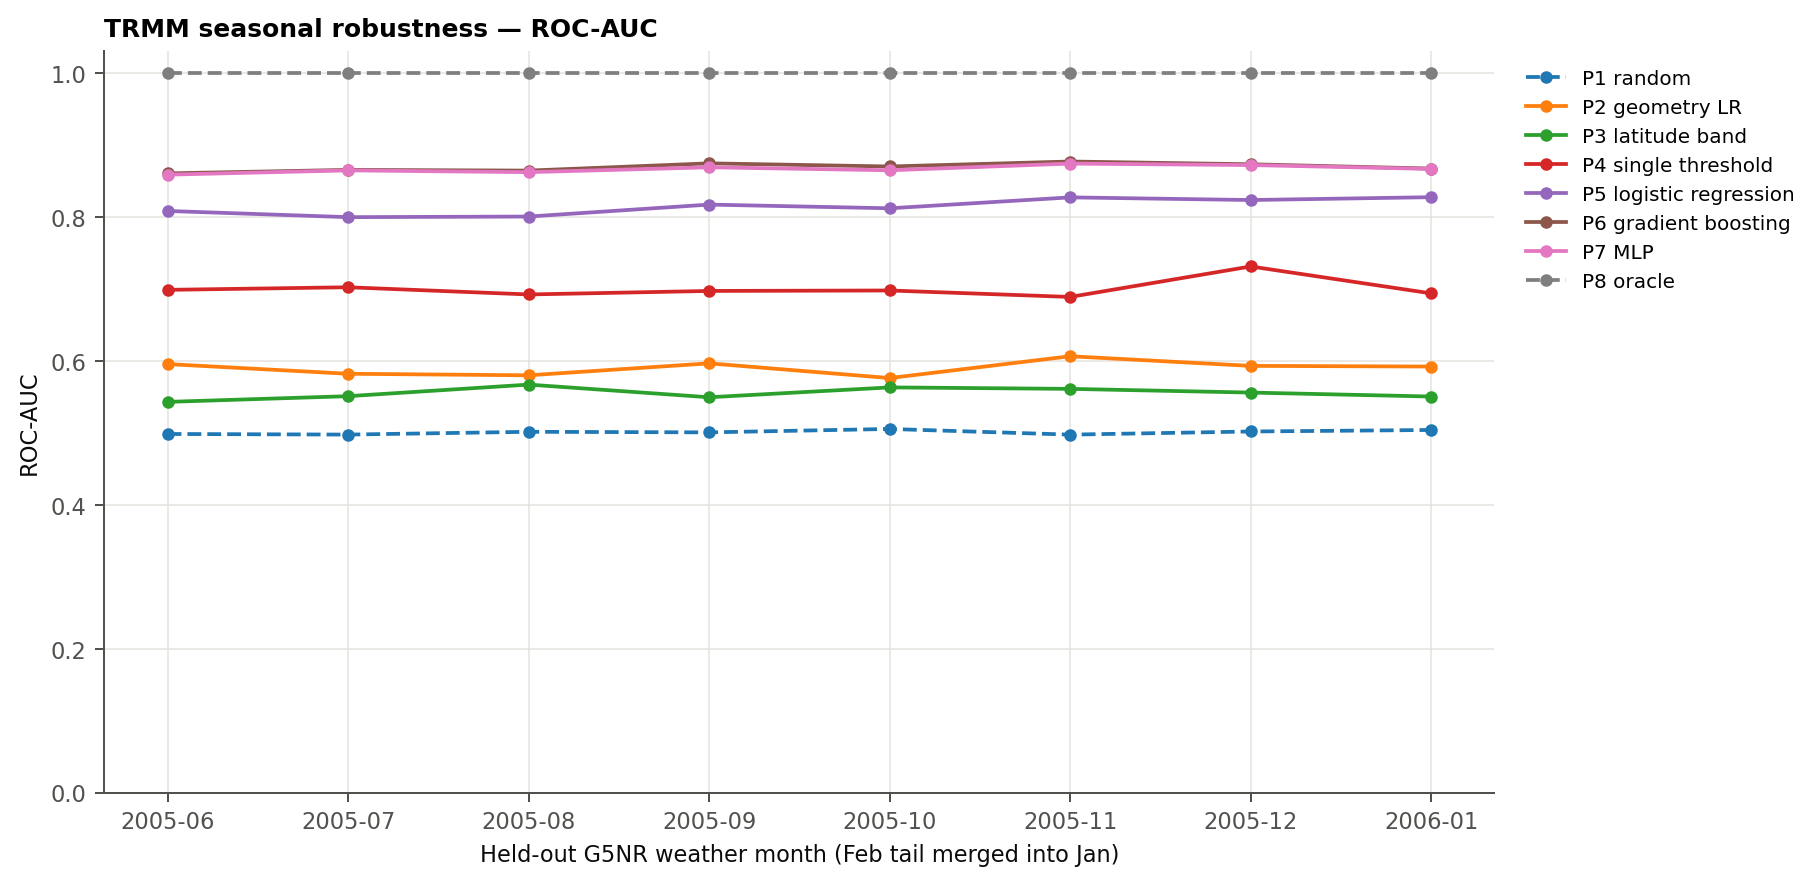

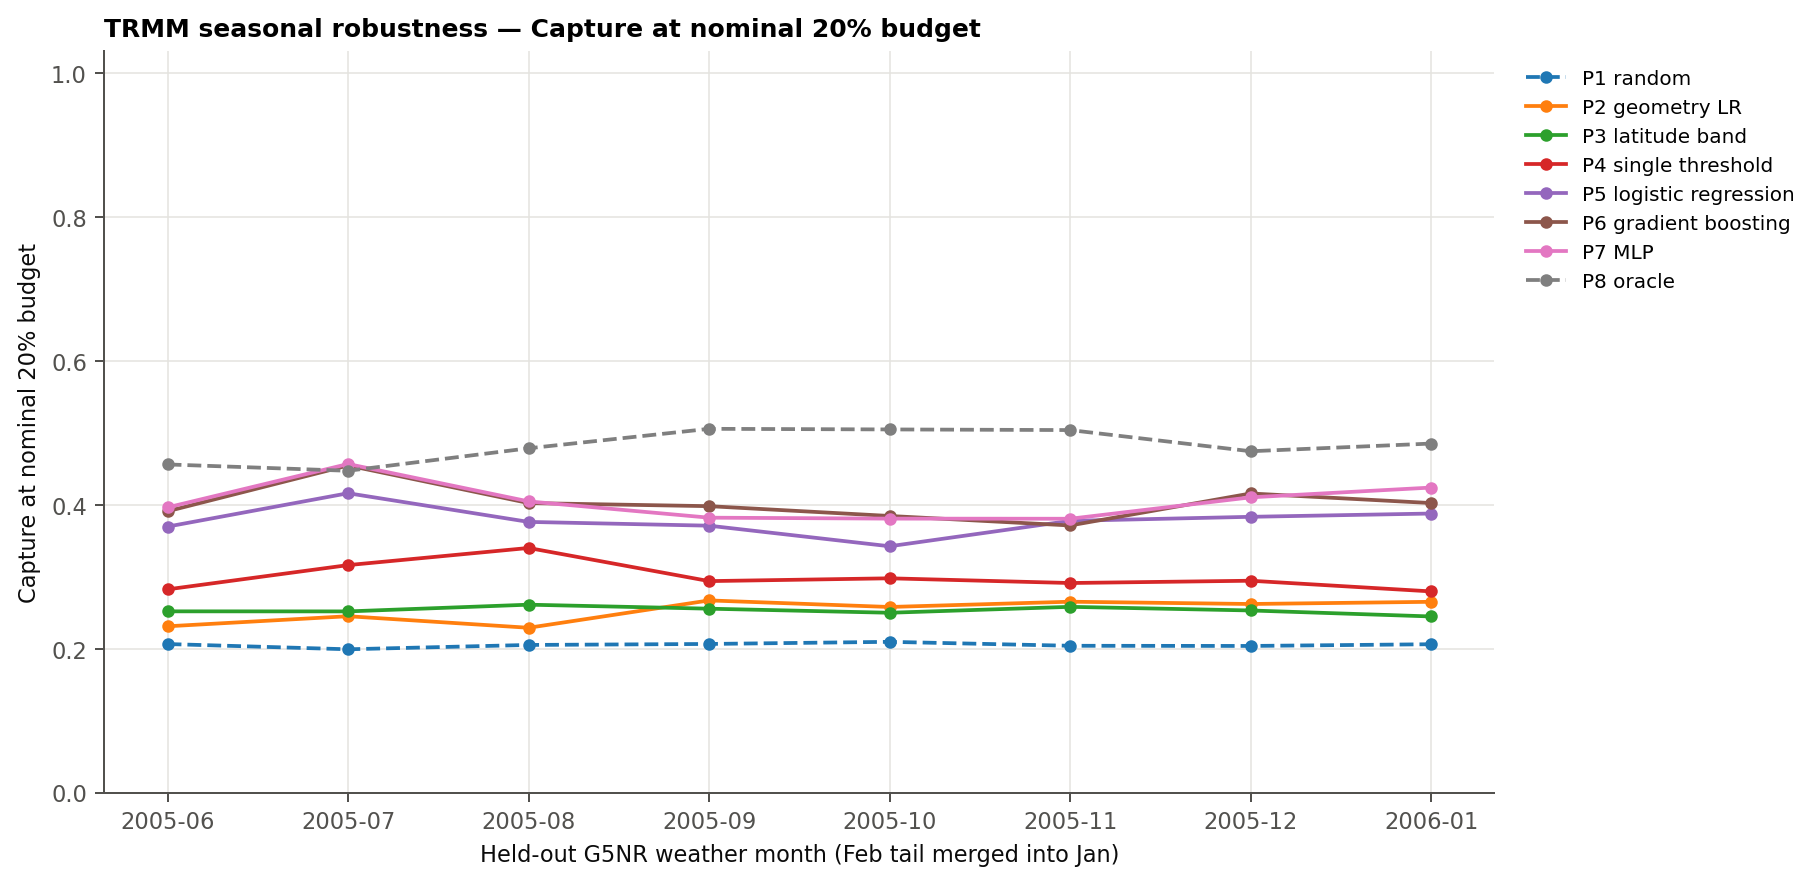

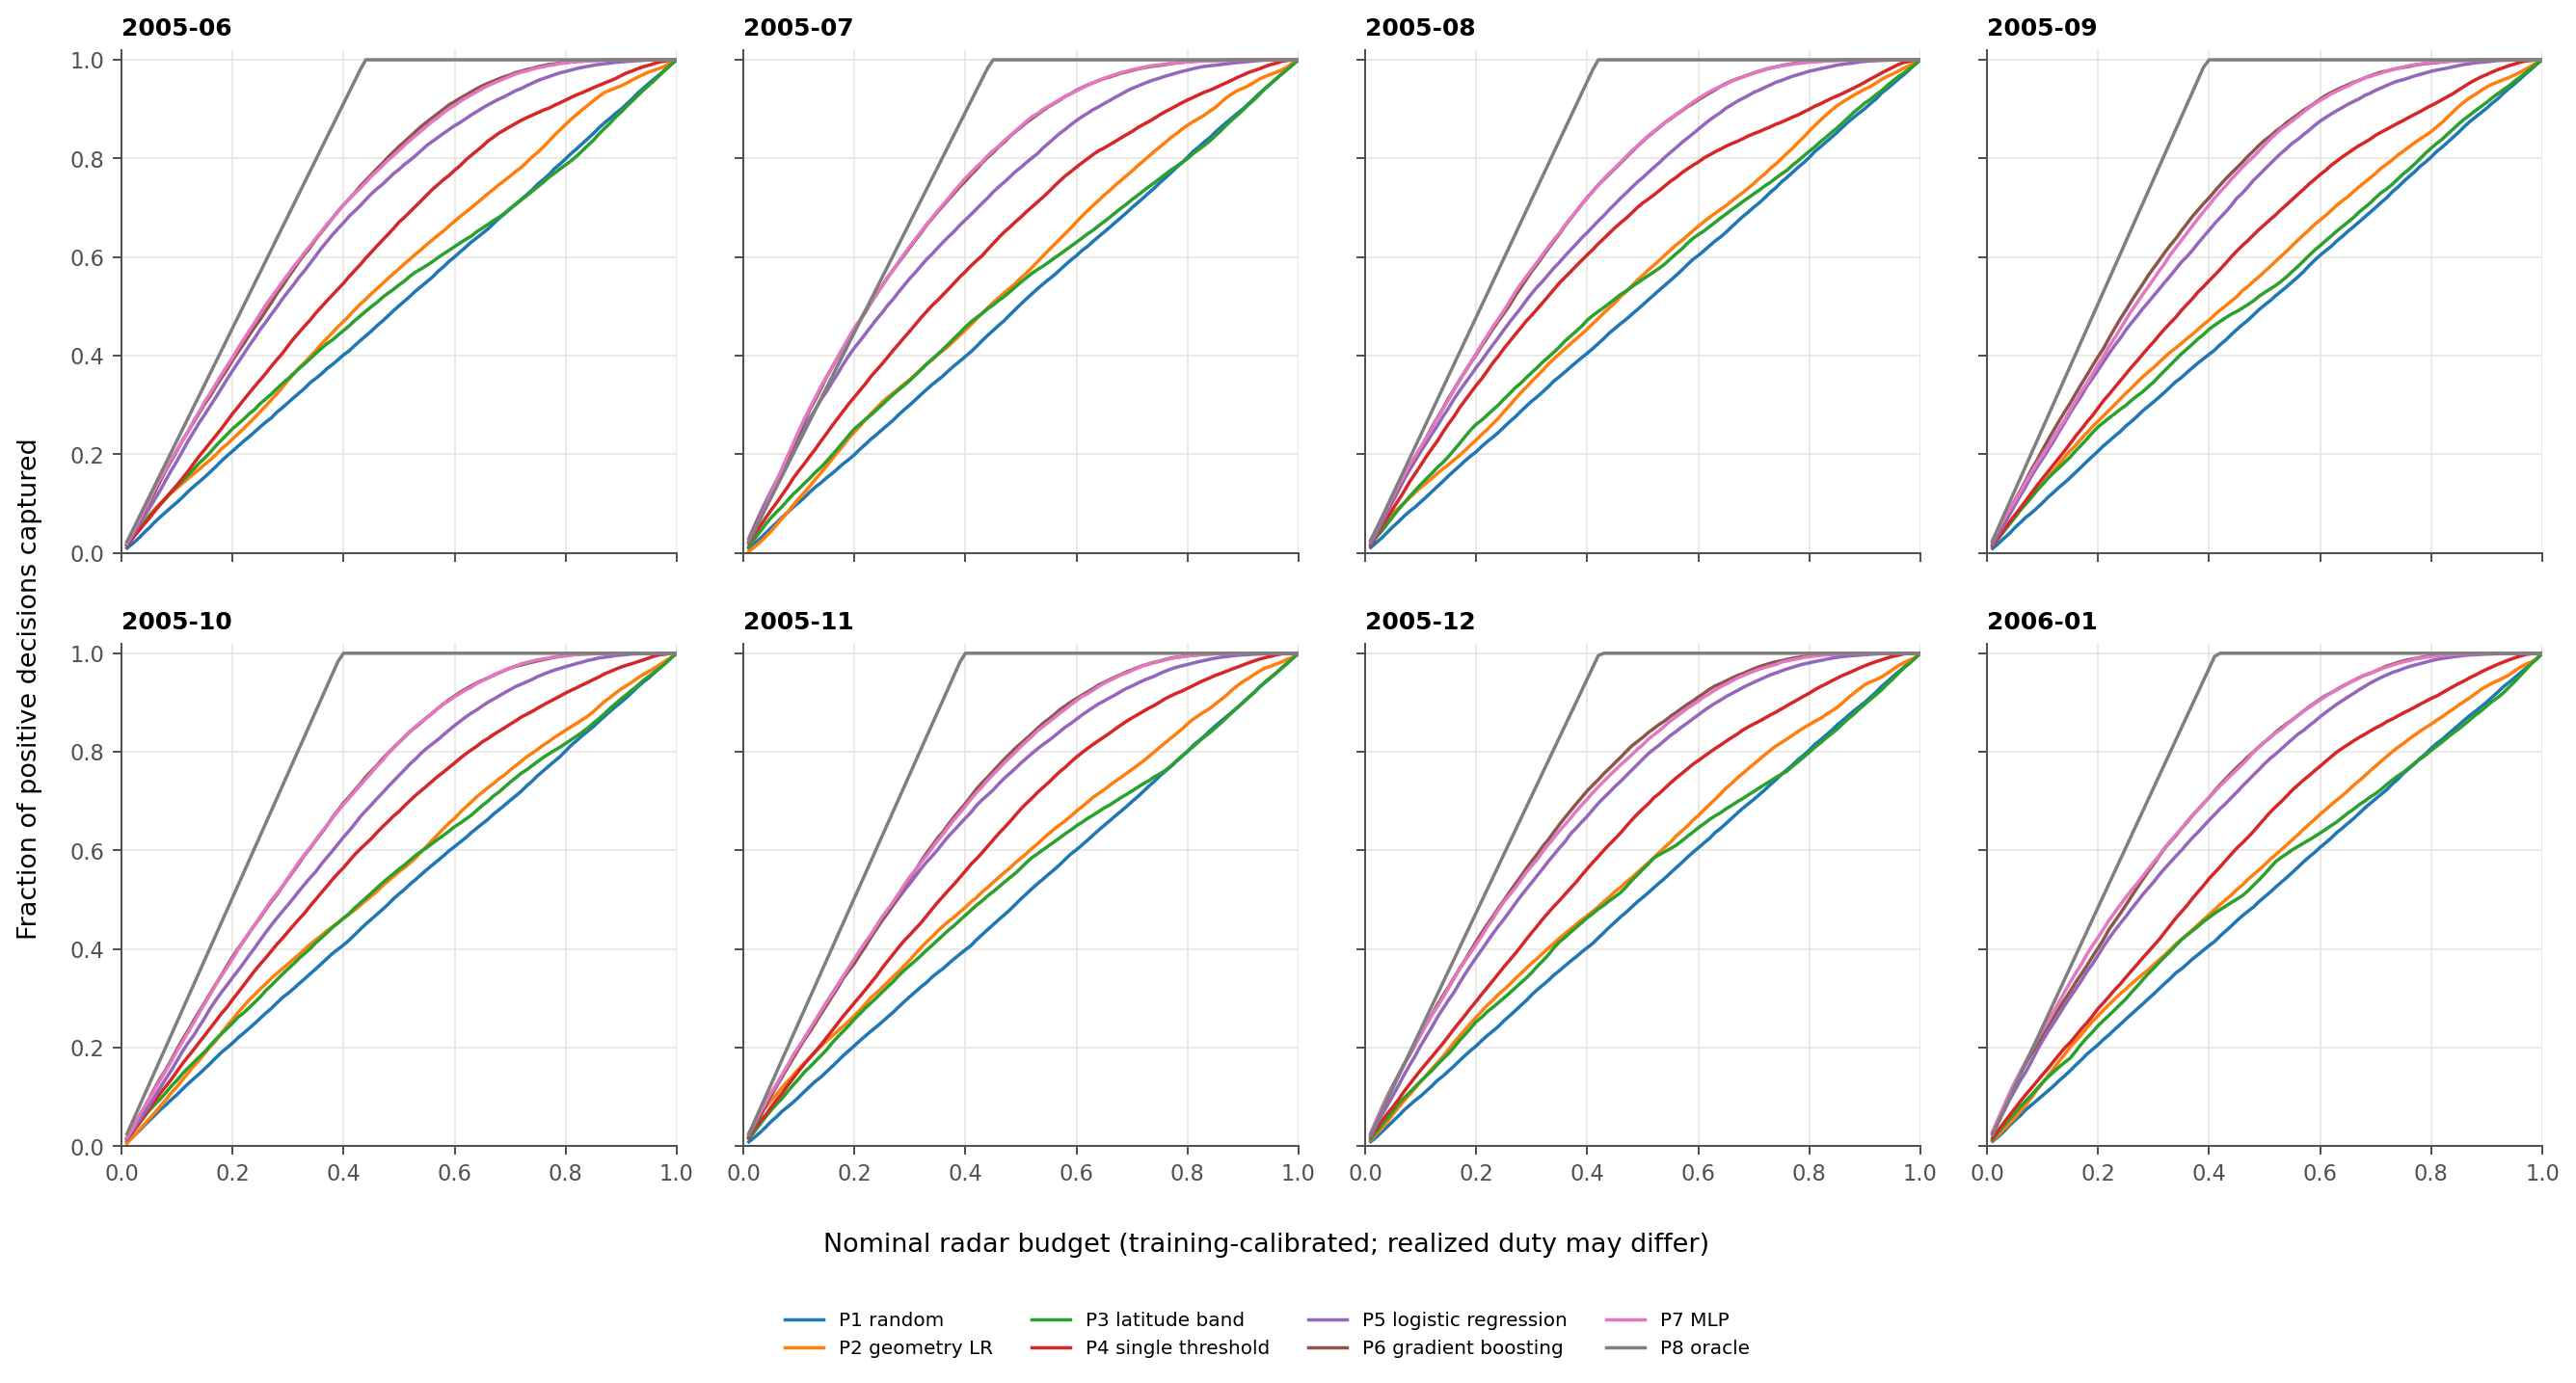

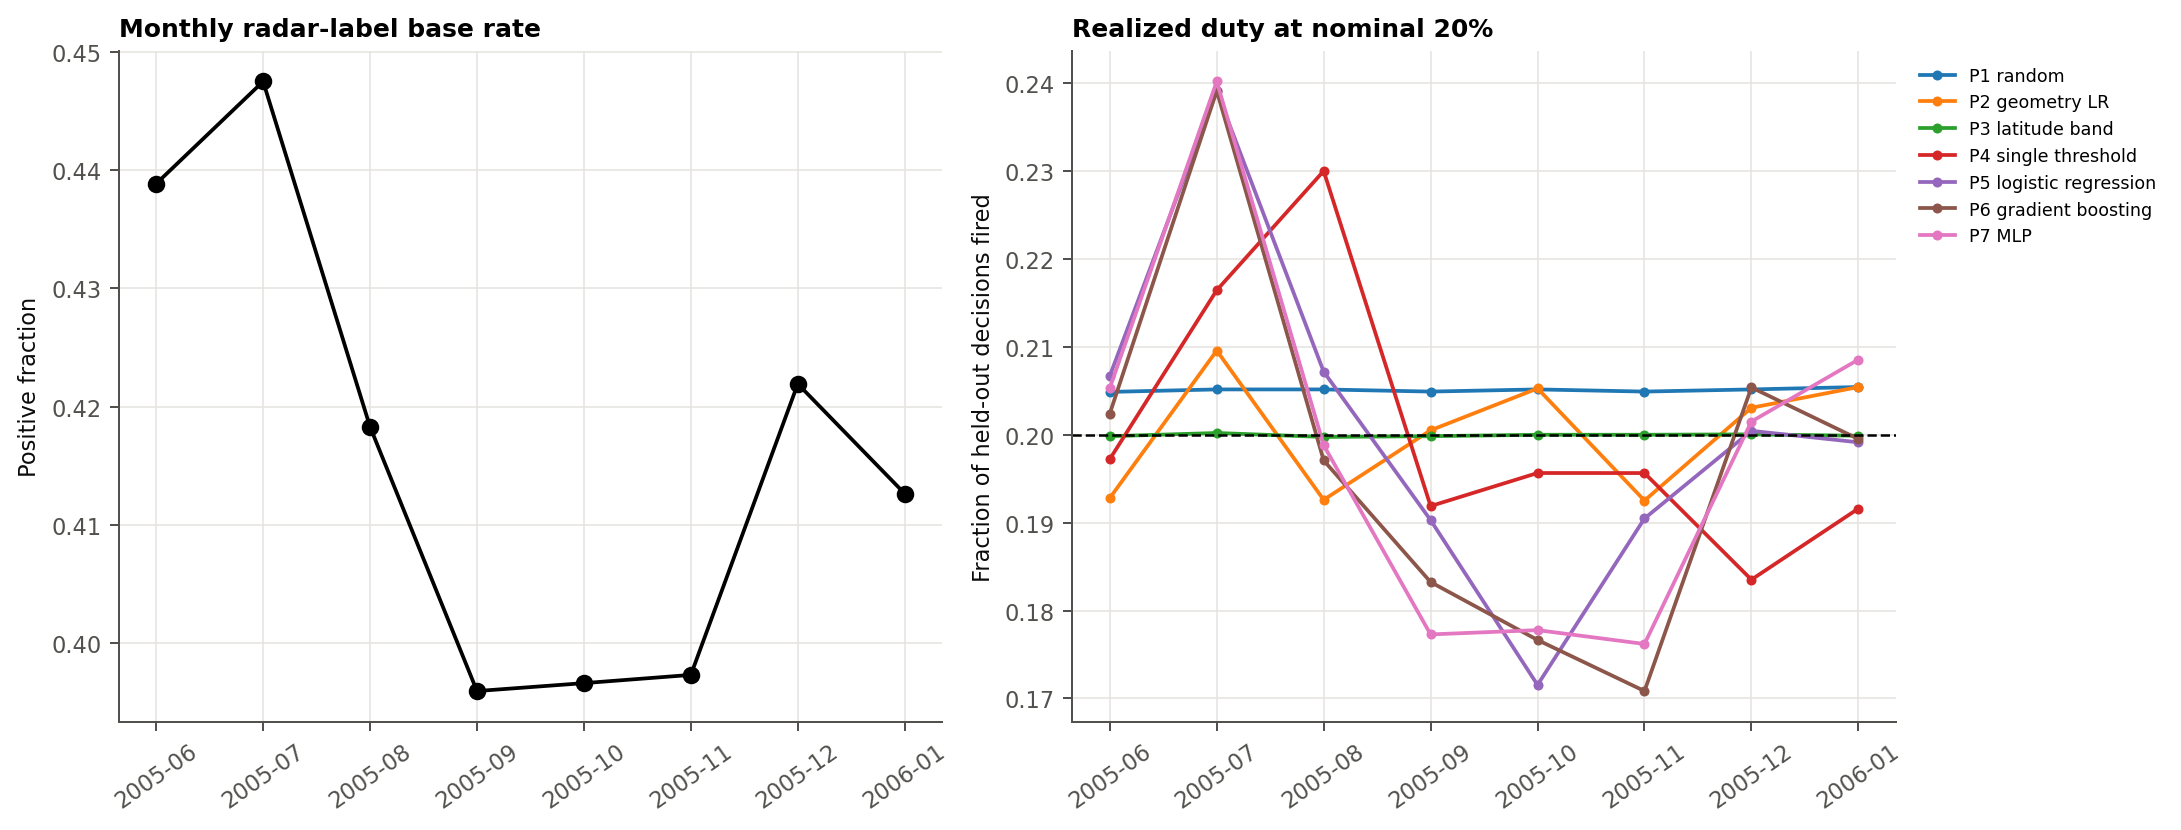

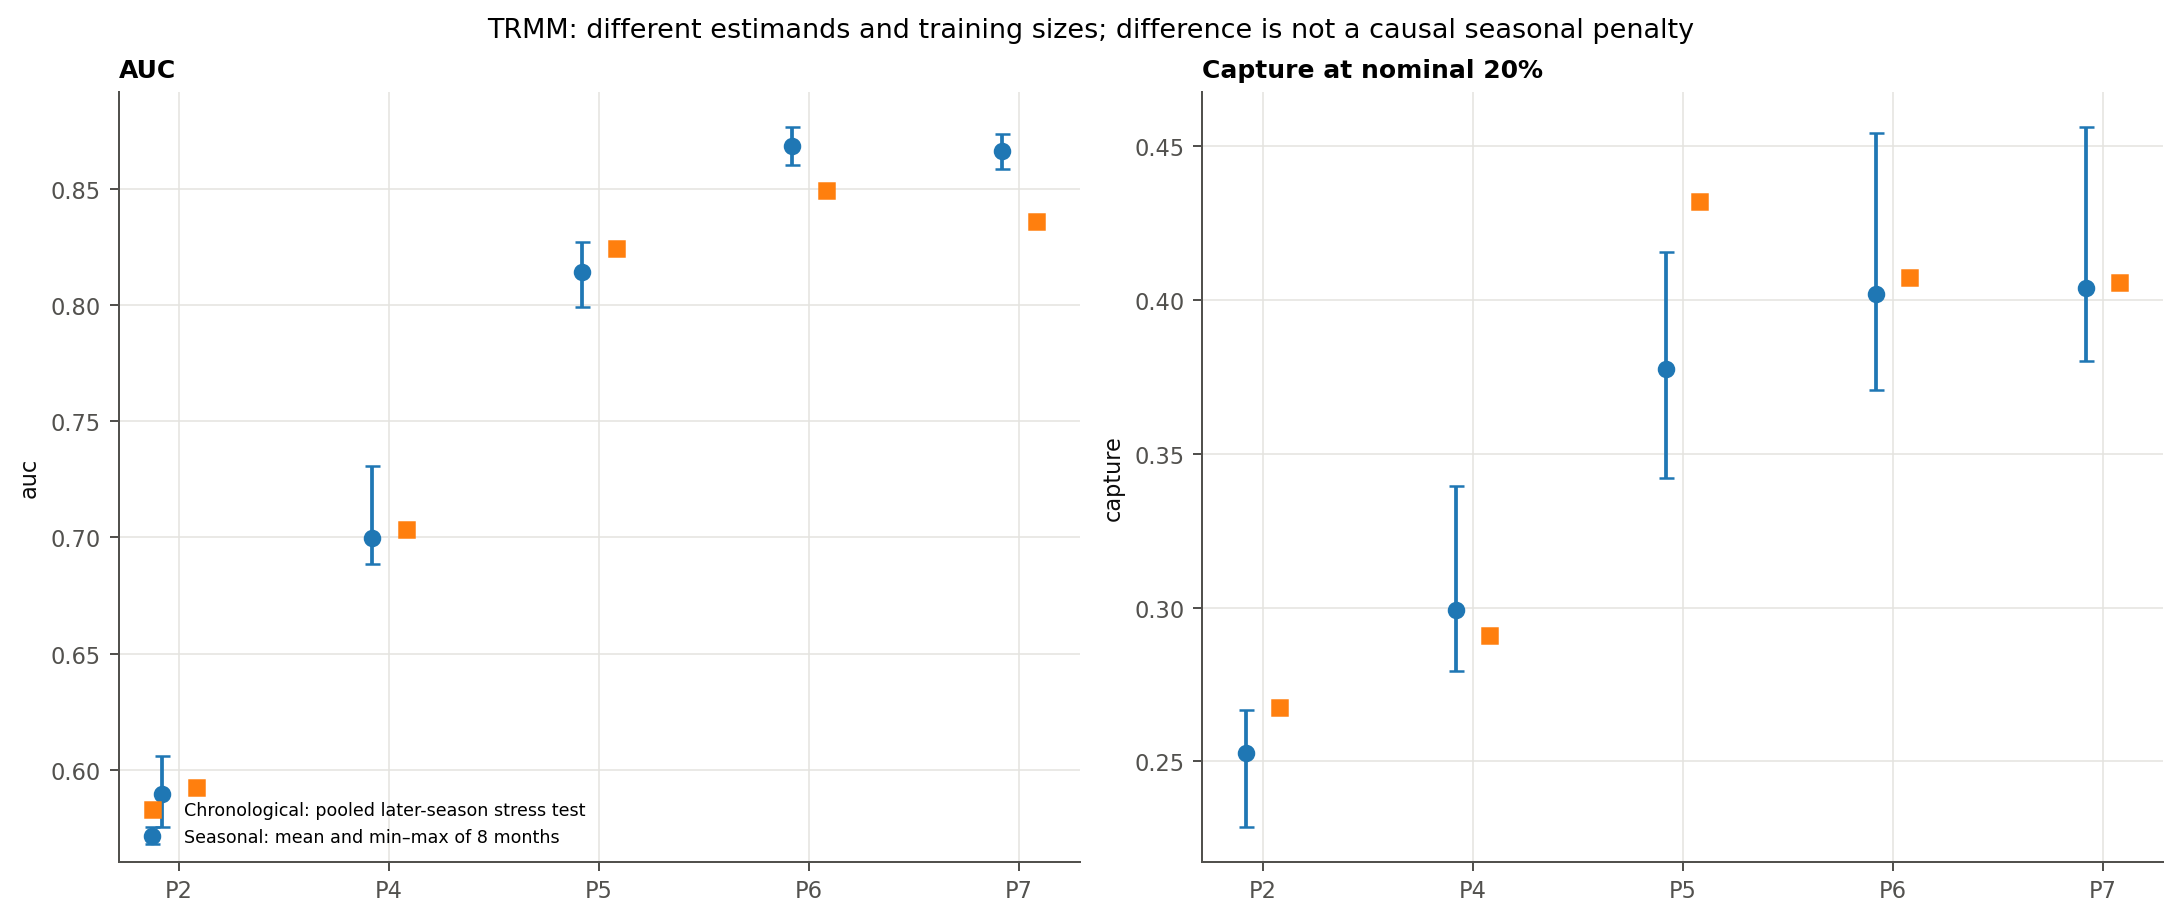

In [2]:
season_monthly = season_read('e2_monthly')
season_20 = season_monthly[(season_monthly.budget_rule == 'fixed') & np.isclose(season_monthly.nominal_budget, .20)]
with pd.option_context('display.max_rows', None):
    display(season_20[['held_out_month','policy','n_train','n_test','base_rate','nominal_budget','realized_duty','auc','average_precision','capture','mass_capture','precision']].round(4))
season_summary = season_read('e2_summary')
for metrics in [('auc','average_precision'),('capture','mass_capture'),('precision','realized_duty','base_rate')]:
    columns = ['policy','nominal_budget'] + [f'{metric}_{stat}' for metric in metrics for stat in ['mean','std','min','max']]
    display(season_summary.loc[np.isclose(season_summary.nominal_budget, .20), columns].round(4))
SEASON_FIG = SEASON_ROOT / 'docs/baseline_paper/figures' / SEASON_MISSION.name / 'seasonal_lomo'
for filename in ['monthly_auc.png','monthly_capture.png','seasonal_capture_curves.png','monthly_base_rate_and_duty.png','chronological_vs_seasonal.png']:
    display(Image(filename=str(SEASON_FIG / filename)))


## E4–E8: geometry, illumination, geography, labels and availability

Every table retains the held-out weather month. E6 uses the global training-fold threshold without
stratum retuning. E7 median labels and base-rate budgets are defined on training rows. E8 records
availability before fitting, including whether each feature can receive a training-fitted missing
indicator. Full tables remain in the CSVs; the displays below expose all monthly records.


In [3]:
for experiment in ['e4_label_geometry','e5_tiers','e6_strata','e7_label_sensitivity','e8_missing_data']:
    display(Markdown('### ' + experiment))
    table = season_read(experiment)
    if 'nominal_budget' in table:
        table = table[np.isclose(table.nominal_budget, .20)]
    with pd.option_context('display.max_rows', None):
        display(table.drop(columns=['dataset_hash','train_months','buffer_steps'], errors='ignore').round(4))


### e4_label_geometry

,mission,held_out_month,n_train,n_test,seed,protocol,threshold_source,policy,variable,trained_on,scored_on,mass_column,duty,capture,mass_capture,precision,base_rate,lift,auc,average_precision,nominal_budget,realized_duty,score_threshold
0,trmm,2005-06,310470,42240,0,seasonal_lomo_v1,training_months_in_sample_score_quantile,P6 gradient boosting,prectot,prectot_radar,prectot_radar,prectot_radar,0.2024,0.3907,0.5517,0.8470,0.4389,1.9300,0.8600,0.8095,0.2,0.2024,0.7339
1,trmm,2005-06,310470,42240,0,seasonal_lomo_v1,training_months_in_sample_score_quantile,P6 gradient boosting,prectot,prectot_radar,prectot_swath,prectot_swath,0.2024,0.2970,0.4665,0.9737,0.6637,1.4670,0.9051,0.9411,0.2,0.2024,0.7339
2,trmm,2005-06,310470,42240,0,seasonal_lomo_v1,training_months_in_sample_score_quantile,P6 gradient boosting,prectot,prectot_radar,prectot_nadir,prectot_nadir,0.2024,0.5557,0.5933,0.4393,0.1600,2.7454,0.8376,0.4963,0.2,0.2024,0.7339
3,trmm,2005-06,310470,42240,0,seasonal_lomo_v1,training_months_in_sample_score_quantile,P6 gradient boosting,prectot,prectot_swath,prectot_radar,prectot_radar,0.2003,0.3807,0.5985,0.8344,0.4389,1.9012,0.8504,0.7938,0.2,0.2003,0.9419
4,trmm,2005-06,310470,42240,0,seasonal_lomo_v1,training_months_in_sample_score_quantile,P6 gradient boosting,prectot,prectot_swath,prectot_swath,prectot_swath,0.2003,0.2937,0.5190,0.9734,0.6637,1.4666,0.9092,0.9430,0.2,0.2003,0.9419
5,trmm,2005-06,310470,42240,0,seasonal_lomo_v1,training_months_in_sample_score_quantile,P6 gradient boosting,prectot,prectot_swath,prectot_nadir,prectot_nadir,0.2003,0.5385,0.6207,0.4303,0.1600,2.6892,0.8265,0.4642,0.2,0.2003,0.9419
6,trmm,2005-06,310470,42240,0,seasonal_lomo_v1,training_months_in_sample_score_quantile,P6 gradient boosting,prectot,prectot_nadir,prectot_radar,prectot_radar,0.2110,0.3993,0.5523,0.8304,0.4389,1.8921,0.8509,0.7958,0.2,0.2110,0.2621
7,trmm,2005-06,310470,42240,0,seasonal_lomo_v1,training_months_in_sample_score_quantile,P6 gradient boosting,prectot,prectot_nadir,prectot_swath,prectot_swath,0.2110,0.3064,0.4679,0.9635,0.6637,1.4518,0.8961,0.9333,0.2,0.2110,0.2621
8,trmm,2005-06,310470,42240,0,seasonal_lomo_v1,training_months_in_sample_score_quantile,P6 gradient boosting,prectot,prectot_nadir,prectot_nadir,prectot_nadir,0.2110,0.5814,0.6139,0.4409,0.1600,2.7553,0.8404,0.5158,0.2,0.2110,0.2621
9,trmm,2005-06,310470,42240,0,seasonal_lomo_v1,training_months_in_sample_score_quantile,P6 gradient boosting,preccon,preccon_radar,preccon_radar,preccon_radar,0.1953,0.7347,0.7749,0.4446,0.1182,3.7627,0.9100,0.5554,0.2,0.1953,0.2269


### e5_tiers

,mission,held_out_month,n_train,n_test,seed,protocol,threshold_source,policy,tier,regime,status,duty,capture,mass_capture,precision,base_rate,lift,auc,average_precision,nominal_budget,realized_duty,score_threshold
19,trmm,2005-06,155213,21119,0,seasonal_lomo_v1,training_months_in_sample_score_quantile,P6 gradient boosting,A,day,ok,0.1885,0.3813,0.6383,0.8543,0.4223,2.0230,0.8631,0.8070,0.2,0.1885,0.7260
100,trmm,2005-06,310470,42240,0,seasonal_lomo_v1,training_months_in_sample_score_quantile,P6 gradient boosting,A,night,not_available_optical_depth_at_night,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.2,NaN,NaN
104,trmm,2005-06,310470,42240,0,seasonal_lomo_v1,training_months_in_sample_score_quantile,P6 gradient boosting,A,switched,ok,0.1942,0.3617,0.5827,0.8173,0.4389,1.8623,0.8312,0.7749,0.2,0.1942,0.6889
126,trmm,2005-06,155213,21119,0,seasonal_lomo_v1,training_months_in_sample_score_quantile,P6 gradient boosting,A_notau,day,ok,0.2140,0.3883,0.6341,0.7662,0.4223,1.8143,0.8044,0.7326,0.2,0.2140,0.6407
226,trmm,2005-06,155257,21121,0,seasonal_lomo_v1,training_months_in_sample_score_quantile,P6 gradient boosting,A_notau,night,ok,0.1998,0.3425,0.5371,0.7806,0.4555,1.7139,0.7945,0.7392,0.2,0.1998,0.6592
310,trmm,2005-06,310470,42240,0,seasonal_lomo_v1,training_months_in_sample_score_quantile,P6 gradient boosting,A_notau,switched,ok,0.2068,0.3654,0.5869,0.7755,0.4389,1.7670,0.7999,0.7361,0.2,0.2068,0.6511
332,trmm,2005-06,155213,21119,0,seasonal_lomo_v1,training_months_in_sample_score_quantile,P6 gradient boosting,B,day,ok,0.2215,0.3962,0.6503,0.7554,0.4223,1.7889,0.7938,0.7189,0.2,0.2215,0.6226
432,trmm,2005-06,155257,21121,0,seasonal_lomo_v1,training_months_in_sample_score_quantile,P6 gradient boosting,B,night,ok,0.2061,0.3422,0.5528,0.7563,0.4555,1.6604,0.7776,0.7191,0.2,0.2061,0.6427
516,trmm,2005-06,310470,42240,0,seasonal_lomo_v1,training_months_in_sample_score_quantile,P6 gradient boosting,B,switched,ok,0.2127,0.3677,0.5993,0.7588,0.4389,1.7289,0.7862,0.7191,0.2,0.2127,0.6340
538,trmm,2005-06,155213,21119,0,seasonal_lomo_v1,training_months_in_sample_score_quantile,P6 gradient boosting,C,day,ok,0.2132,0.3356,0.3912,0.6648,0.4223,1.5744,0.7246,0.6383,0.2,0.2132,0.5686


### e6_strata

,mission,held_out_month,n_train,n_test,seed,protocol,threshold_source,policy,stratum,threshold_scope,duty,capture,mass_capture,precision,base_rate,lift,auc,average_precision,nominal_budget,realized_duty,score_threshold
3,trmm,2005-06,310470,8217,0,seasonal_lomo_v1,training_months_in_sample_score_quantile,P6 gradient boosting,deep tropics |lat|<10,global_training_fold,0.2805,0.4572,0.6064,0.8525,0.5231,1.6298,0.8339,0.8361,0.2,0.2805,0.7339
9,trmm,2005-06,310470,12303,0,seasonal_lomo_v1,training_months_in_sample_score_quantile,P6 gradient boosting,outer tropics 10-23.5,global_training_fold,0.1887,0.3524,0.5652,0.8376,0.4484,1.8678,0.8490,0.7947,0.2,0.1887,0.7339
15,trmm,2005-06,310470,21720,0,seasonal_lomo_v1,training_months_in_sample_score_quantile,P6 gradient boosting,subtropics >=23.5,global_training_fold,0.1807,0.3821,0.6683,0.8494,0.4016,2.1150,0.8727,0.8044,0.2,0.1807,0.7339
21,trmm,2005-06,310470,28500,0,seasonal_lomo_v1,training_months_in_sample_score_quantile,P6 gradient boosting,ocean,global_training_fold,0.1940,0.3365,0.5596,0.8319,0.4796,1.7346,0.8195,0.7844,0.2,0.1940,0.7339
27,trmm,2005-06,310470,8965,0,seasonal_lomo_v1,training_months_in_sample_score_quantile,P6 gradient boosting,land,global_training_fold,0.1769,0.5128,0.7762,0.8827,0.3045,2.8988,0.9330,0.8548,0.2,0.1769,0.7339
33,trmm,2005-06,310470,4775,0,seasonal_lomo_v1,training_months_in_sample_score_quantile,P6 gradient boosting,mixed,global_training_fold,0.3007,0.5811,0.7890,0.8656,0.4480,1.9323,0.9023,0.8732,0.2,0.3007,0.7339
39,trmm,2005-07,308100,8680,0,seasonal_lomo_v1,training_months_in_sample_score_quantile,P6 gradient boosting,deep tropics |lat|<10,global_training_fold,0.3006,0.4979,0.6899,0.8651,0.5222,1.6565,0.8434,0.8453,0.2,0.3006,0.7303
45,trmm,2005-07,308100,12986,0,seasonal_lomo_v1,training_months_in_sample_score_quantile,P6 gradient boosting,outer tropics 10-23.5,global_training_fold,0.2493,0.4495,0.6664,0.8586,0.4762,1.8029,0.8631,0.8341,0.2,0.2493,0.7303
51,trmm,2005-07,308100,22914,0,seasonal_lomo_v1,training_months_in_sample_score_quantile,P6 gradient boosting,subtropics >=23.5,global_training_fold,0.2101,0.4360,0.6923,0.8363,0.4030,2.0753,0.8712,0.8016,0.2,0.2101,0.7303
57,trmm,2005-07,308100,30110,0,seasonal_lomo_v1,training_months_in_sample_score_quantile,P6 gradient boosting,ocean,global_training_fold,0.2233,0.3971,0.6130,0.8395,0.4722,1.7780,0.8327,0.7981,0.2,0.2233,0.7303


### e7_label_sensitivity

,mission,held_out_month,n_train,n_test,seed,protocol,threshold_source,policy,label,label_column,label_threshold,training_base_rate,label_threshold_source,status,duty,capture,mass_capture,precision,base_rate,lift,auc,average_precision,nominal_budget,realized_duty,score_threshold
3,trmm,2005-06,310470,42240,0,seasonal_lomo_v1,training_months_in_sample_score_quantile,P5 logistic regression,rain_0.1_mm_hr,prectot_radar,0.0000,0.7497,prespecified_physical_threshold,ok,0.2001,0.2608,0.5497,0.9875,0.7576,1.3034,0.9199,0.9675,0.2,0.2001,0.9903
10,trmm,2005-06,310470,42240,0,seasonal_lomo_v1,training_months_in_sample_score_quantile,P6 gradient boosting,rain_0.1_mm_hr,prectot_radar,0.0000,0.7497,prespecified_physical_threshold,ok,0.1946,0.2567,0.6092,0.9993,0.7576,1.3190,0.9487,0.9820,0.2,0.1946,0.9913
17,trmm,2005-06,310470,42240,0,seasonal_lomo_v1,training_months_in_sample_score_quantile,P5 logistic regression,rain_1_mm_hr,prectot_radar,0.0003,0.4130,prespecified_physical_threshold,ok,0.2067,0.3693,0.5643,0.7842,0.4389,1.7869,0.8078,0.7302,0.2,0.2067,0.6825
24,trmm,2005-06,310470,42240,0,seasonal_lomo_v1,training_months_in_sample_score_quantile,P6 gradient boosting,rain_1_mm_hr,prectot_radar,0.0003,0.4130,prespecified_physical_threshold,ok,0.2024,0.3907,0.5517,0.8470,0.4389,1.9300,0.8600,0.8095,0.2,0.2024,0.7339
31,trmm,2005-06,310470,42240,0,seasonal_lomo_v1,training_months_in_sample_score_quantile,P5 logistic regression,rain_5_mm_hr,prectot_radar,0.0014,0.2165,prespecified_physical_threshold,ok,0.2084,0.5217,0.6017,0.5620,0.2245,2.5038,0.8288,0.5494,0.2,0.2084,0.4014
38,trmm,2005-06,310470,42240,0,seasonal_lomo_v1,training_months_in_sample_score_quantile,P6 gradient boosting,rain_5_mm_hr,prectot_radar,0.0014,0.2165,prespecified_physical_threshold,ok,0.2065,0.5573,0.6227,0.6057,0.2245,2.6985,0.8682,0.6361,0.2,0.2065,0.4339
45,trmm,2005-06,310470,42240,0,seasonal_lomo_v1,training_months_in_sample_score_quantile,P5 logistic regression,convective_1_mm_hr,preccon_radar,0.0003,0.1155,prespecified_physical_threshold,ok,0.2079,0.6938,0.7279,0.3944,0.1182,3.3377,0.8793,0.4433,0.2,0.2079,0.2118
52,trmm,2005-06,310470,42240,0,seasonal_lomo_v1,training_months_in_sample_score_quantile,P6 gradient boosting,convective_1_mm_hr,preccon_radar,0.0003,0.1155,prespecified_physical_threshold,ok,0.1953,0.7347,0.7749,0.4446,0.1182,3.7627,0.9100,0.5554,0.2,0.1953,0.2269
59,trmm,2005-06,310470,42240,0,seasonal_lomo_v1,training_months_in_sample_score_quantile,P5 logistic regression,training_median_split,prectot_radar,0.0002,0.5000,training_median,ok,0.2046,0.3375,0.5630,0.8652,0.5244,1.6498,0.8314,0.8138,0.2,0.2046,0.8033
66,trmm,2005-06,310470,42240,0,seasonal_lomo_v1,training_months_in_sample_score_quantile,P6 gradient boosting,training_median_split,prectot_radar,0.0002,0.5000,training_median,ok,0.2035,0.3547,0.5788,0.9139,0.5244,1.7427,0.8762,0.8712,0.2,0.2035,0.8320


### e8_missing_data

,mission,held_out_month,n_train,n_test,seed,protocol,threshold_source,partition,item,n_rows,missing_count,available_count,availability,training_missing_indicator,note
0,trmm,2005-06,310470,42240,0,seasonal_lomo_v1,training_months_in_sample_score_quantile,train,cldtot_mean,310470,0,310470,1.0000,False,LR/MLP imputer/scaler/indicators fitted on tra...
1,trmm,2005-06,310470,42240,0,seasonal_lomo_v1,training_months_in_sample_score_quantile,train,cldtmp_mean,310470,5484,304986,0.9823,True,LR/MLP imputer/scaler/indicators fitted on tra...
2,trmm,2005-06,310470,42240,0,seasonal_lomo_v1,training_months_in_sample_score_quantile,train,tautot_mean,310470,0,310470,1.0000,False,LR/MLP imputer/scaler/indicators fitted on tra...
3,trmm,2005-06,310470,42240,0,seasonal_lomo_v1,training_months_in_sample_score_quantile,train,tautot_max,310470,0,310470,1.0000,False,LR/MLP imputer/scaler/indicators fitted on tra...
4,trmm,2005-06,310470,42240,0,seasonal_lomo_v1,training_months_in_sample_score_quantile,train,lwtup_mean,310470,0,310470,1.0000,False,LR/MLP imputer/scaler/indicators fitted on tra...
5,trmm,2005-06,310470,42240,0,seasonal_lomo_v1,training_months_in_sample_score_quantile,train,lat,310470,0,310470,1.0000,False,LR/MLP imputer/scaler/indicators fitted on tra...
6,trmm,2005-06,310470,42240,0,seasonal_lomo_v1,training_months_in_sample_score_quantile,train,sin_sh,310470,0,310470,1.0000,False,LR/MLP imputer/scaler/indicators fitted on tra...
7,trmm,2005-06,310470,42240,0,seasonal_lomo_v1,training_months_in_sample_score_quantile,train,cos_sh,310470,0,310470,1.0000,False,LR/MLP imputer/scaler/indicators fitted on tra...
8,trmm,2005-06,310470,42240,0,seasonal_lomo_v1,training_months_in_sample_score_quantile,train,sin_lon,310470,0,310470,1.0000,False,LR/MLP imputer/scaler/indicators fitted on tra...
9,trmm,2005-06,310470,42240,0,seasonal_lomo_v1,training_months_in_sample_score_quantile,train,cos_lon,310470,0,310470,1.0000,False,LR/MLP imputer/scaler/indicators fitted on tra...


## E10/E11: within-month uncertainty and seasonal importance

Bootstrap resamples whole days inside each held-out month with gates fixed. P6 is a prespecified
paired-comparison and permutation-importance reference. Across-fold summaries of confidence-bound
endpoints are descriptive, not a confidence interval for a pooled all-season mean. Single-feature
score direction is chosen using training labels only. E1 and E9 retain the historical leakage
comparison and architecture-cost measurements separately below.


### e10_bootstrap

,mission,held_out_month,n_train,n_test,seed,protocol,threshold_source,policy,metric,mean,ci_low,ci_high,n_boot,n_boot_valid,n_days,resampling
0,trmm,2005-06,310470,42240,0,seasonal_lomo_v1,training_months_in_sample_score_quantile,P1 random,auc,0.4981,0.4914,0.5041,1000,1000,30,whole G5NR days within held-out month; fixed gate
1,trmm,2005-06,310470,42240,0,seasonal_lomo_v1,training_months_in_sample_score_quantile,P1 random,average_precision,0.4389,0.4317,0.4461,1000,1000,30,whole G5NR days within held-out month; fixed gate
2,trmm,2005-06,310470,42240,0,seasonal_lomo_v1,training_months_in_sample_score_quantile,P1 random,capture@13%,0.1346,0.1294,0.1402,1000,1000,30,whole G5NR days within held-out month; fixed gate
3,trmm,2005-06,310470,42240,0,seasonal_lomo_v1,training_months_in_sample_score_quantile,P1 random,mass_capture@13%,0.1349,0.1253,0.1450,1000,1000,30,whole G5NR days within held-out month; fixed gate
4,trmm,2005-06,310470,42240,0,seasonal_lomo_v1,training_months_in_sample_score_quantile,P1 random,precision@13%,0.4429,0.4315,0.4540,1000,1000,30,whole G5NR days within held-out month; fixed gate
5,trmm,2005-06,310470,42240,0,seasonal_lomo_v1,training_months_in_sample_score_quantile,P1 random,realized_duty@13%,0.1333,0.1301,0.1369,1000,1000,30,whole G5NR days within held-out month; fixed gate
6,trmm,2005-06,310470,42240,0,seasonal_lomo_v1,training_months_in_sample_score_quantile,P1 random,capture@20%,0.2063,0.2000,0.2132,1000,1000,30,whole G5NR days within held-out month; fixed gate
7,trmm,2005-06,310470,42240,0,seasonal_lomo_v1,training_months_in_sample_score_quantile,P1 random,mass_capture@20%,0.2011,0.1917,0.2118,1000,1000,30,whole G5NR days within held-out month; fixed gate
8,trmm,2005-06,310470,42240,0,seasonal_lomo_v1,training_months_in_sample_score_quantile,P1 random,precision@20%,0.4417,0.4319,0.4524,1000,1000,30,whole G5NR days within held-out month; fixed gate
9,trmm,2005-06,310470,42240,0,seasonal_lomo_v1,training_months_in_sample_score_quantile,P1 random,realized_duty@20%,0.2049,0.2016,0.2084,1000,1000,30,whole G5NR days within held-out month; fixed gate


### e10_bootstrap_summary

,mission,policy,metric,mean_mean,mean_std,mean_min,mean_max,mean_count,ci_low_mean,ci_low_std,ci_low_min,ci_low_max,ci_low_count,ci_high_mean,ci_high_std,ci_high_min,ci_high_max,ci_high_count
0,trmm,P1 random,auc,0.5004,0.0029,0.4970,0.5049,8,0.4946,0.0033,0.4906,0.4991,8,0.5061,0.0028,0.5019,0.5106,8
1,trmm,P1 random,average_precision,0.4164,0.0189,0.3945,0.4439,8,0.4086,0.0188,0.3874,0.4364,8,0.4243,0.0191,0.4012,0.4518,8
2,trmm,P1 random,capture@13%,0.1340,0.0014,0.1321,0.1369,8,0.1291,0.0015,0.1277,0.1326,8,0.1392,0.0015,0.1365,0.1414,8
3,trmm,P1 random,capture@20%,0.2049,0.0030,0.1990,0.2092,8,0.1996,0.0030,0.1944,0.2051,8,0.2101,0.0033,0.2031,0.2133,8
4,trmm,P1 random,mass_capture@13%,0.1337,0.0054,0.1254,0.1425,8,0.1254,0.0041,0.1203,0.1324,8,0.1427,0.0070,0.1308,0.1535,8
5,trmm,P1 random,mass_capture@20%,0.2035,0.0065,0.1908,0.2130,8,0.1936,0.0053,0.1833,0.2002,8,0.2138,0.0079,0.1980,0.2264,8
6,trmm,P1 random,precision@13%,0.4172,0.0201,0.3929,0.4474,8,0.4042,0.0199,0.3798,0.4338,8,0.4302,0.0204,0.4053,0.4604,8
7,trmm,P1 random,precision@20%,0.4155,0.0163,0.3953,0.4417,8,0.4049,0.0165,0.3848,0.4319,8,0.4264,0.0165,0.4052,0.4524,8
8,trmm,P1 random,realized_duty@13%,0.1337,0.0002,0.1333,0.1338,8,0.1303,0.0002,0.1299,0.1305,8,0.1371,0.0003,0.1369,0.1378,8
9,trmm,P1 random,realized_duty@20%,0.2051,0.0002,0.2049,0.2055,8,0.2019,0.0002,0.2016,0.2021,8,0.2085,0.0003,0.2082,0.2093,8


### e11_permutation_importance

,mission,held_out_month,n_train,n_test,seed,protocol,threshold_source,policy,feature,auc_drop_mean,auc_drop_std,n_importance,n_repeats
0,trmm,2005-06,310470,42240,0,seasonal_lomo_v1,training_months_in_sample_score_quantile,P6 gradient boosting,cldtot_mean,0.0598,0.0010,42240,5
1,trmm,2005-06,310470,42240,0,seasonal_lomo_v1,training_months_in_sample_score_quantile,P6 gradient boosting,cldtmp_mean,0.0420,0.0009,42240,5
2,trmm,2005-06,310470,42240,0,seasonal_lomo_v1,training_months_in_sample_score_quantile,P6 gradient boosting,tautot_mean,0.1549,0.0020,42240,5
3,trmm,2005-06,310470,42240,0,seasonal_lomo_v1,training_months_in_sample_score_quantile,P6 gradient boosting,tautot_max,0.0634,0.0018,42240,5
4,trmm,2005-06,310470,42240,0,seasonal_lomo_v1,training_months_in_sample_score_quantile,P6 gradient boosting,lwtup_mean,0.0506,0.0007,42240,5
5,trmm,2005-06,310470,42240,0,seasonal_lomo_v1,training_months_in_sample_score_quantile,P6 gradient boosting,lat,0.0166,0.0005,42240,5
6,trmm,2005-06,310470,42240,0,seasonal_lomo_v1,training_months_in_sample_score_quantile,P6 gradient boosting,sin_sh,0.0022,0.0002,42240,5
7,trmm,2005-06,310470,42240,0,seasonal_lomo_v1,training_months_in_sample_score_quantile,P6 gradient boosting,cos_sh,0.0016,0.0002,42240,5
8,trmm,2005-06,310470,42240,0,seasonal_lomo_v1,training_months_in_sample_score_quantile,P6 gradient boosting,sin_lon,0.0091,0.0001,42240,5
9,trmm,2005-06,310470,42240,0,seasonal_lomo_v1,training_months_in_sample_score_quantile,P6 gradient boosting,cos_lon,0.0054,0.0001,42240,5


### e11_permutation_importance_summary

,mission,policy,feature,auc_drop_mean_mean,auc_drop_mean_std,auc_drop_mean_min,auc_drop_mean_max,auc_drop_mean_count
0,trmm,P6 gradient boosting,cldtmp_mean,0.0401,0.0058,0.0329,0.0477,8
1,trmm,P6 gradient boosting,cldtot_mean,0.0593,0.0051,0.0502,0.0664,8
2,trmm,P6 gradient boosting,cos_lon,0.0073,0.0016,0.0048,0.0095,8
3,trmm,P6 gradient boosting,cos_sh,0.0026,0.0007,0.0016,0.0039,8
4,trmm,P6 gradient boosting,land_frac_nadir,0.0194,0.0042,0.0125,0.0244,8
5,trmm,P6 gradient boosting,lat,0.0180,0.0046,0.0087,0.0214,8
6,trmm,P6 gradient boosting,lwtup_mean,0.0491,0.0052,0.0394,0.0537,8
7,trmm,P6 gradient boosting,ocean_frac_nadir,0.0075,0.0022,0.0042,0.0104,8
8,trmm,P6 gradient boosting,sin_lon,0.0092,0.0016,0.0065,0.0109,8
9,trmm,P6 gradient boosting,sin_sh,0.0026,0.0006,0.0019,0.0038,8


### e11_single_feature_auc

,mission,held_out_month,n_train,n_test,seed,protocol,threshold_source,feature,direction_source,sign,n_available_test,auc,average_precision
0,trmm,2005-06,310470,42240,0,seasonal_lomo_v1,training_months_in_sample_score_quantile,cldtmp_mean,training_months_auc,-1,41131,0.5931,0.5167
1,trmm,2005-06,310470,42240,0,seasonal_lomo_v1,training_months_in_sample_score_quantile,cldtot_mean,training_months_auc,1,42240,0.6893,0.6010
2,trmm,2005-06,310470,42240,0,seasonal_lomo_v1,training_months_in_sample_score_quantile,cos_lon,training_months_auc,-1,42240,0.6011,0.5160
3,trmm,2005-06,310470,42240,0,seasonal_lomo_v1,training_months_in_sample_score_quantile,cos_sh,training_months_auc,1,42240,0.5208,0.4548
4,trmm,2005-06,310470,42240,0,seasonal_lomo_v1,training_months_in_sample_score_quantile,land_frac_nadir,training_months_auc,-1,42240,0.5653,0.4749
5,trmm,2005-06,310470,42240,0,seasonal_lomo_v1,training_months_in_sample_score_quantile,lat,training_months_auc,1,42240,0.4569,0.3975
6,trmm,2005-06,310470,42240,0,seasonal_lomo_v1,training_months_in_sample_score_quantile,lwtup_mean,training_months_auc,-1,42240,0.6959,0.6282
7,trmm,2005-06,310470,42240,0,seasonal_lomo_v1,training_months_in_sample_score_quantile,ocean_frac_nadir,training_months_auc,1,42240,0.5657,0.4749
8,trmm,2005-06,310470,42240,0,seasonal_lomo_v1,training_months_in_sample_score_quantile,sin_lon,training_months_auc,-1,42240,0.4877,0.4317
9,trmm,2005-06,310470,42240,0,seasonal_lomo_v1,training_months_in_sample_score_quantile,sin_sh,training_months_auc,1,42240,0.4981,0.4356


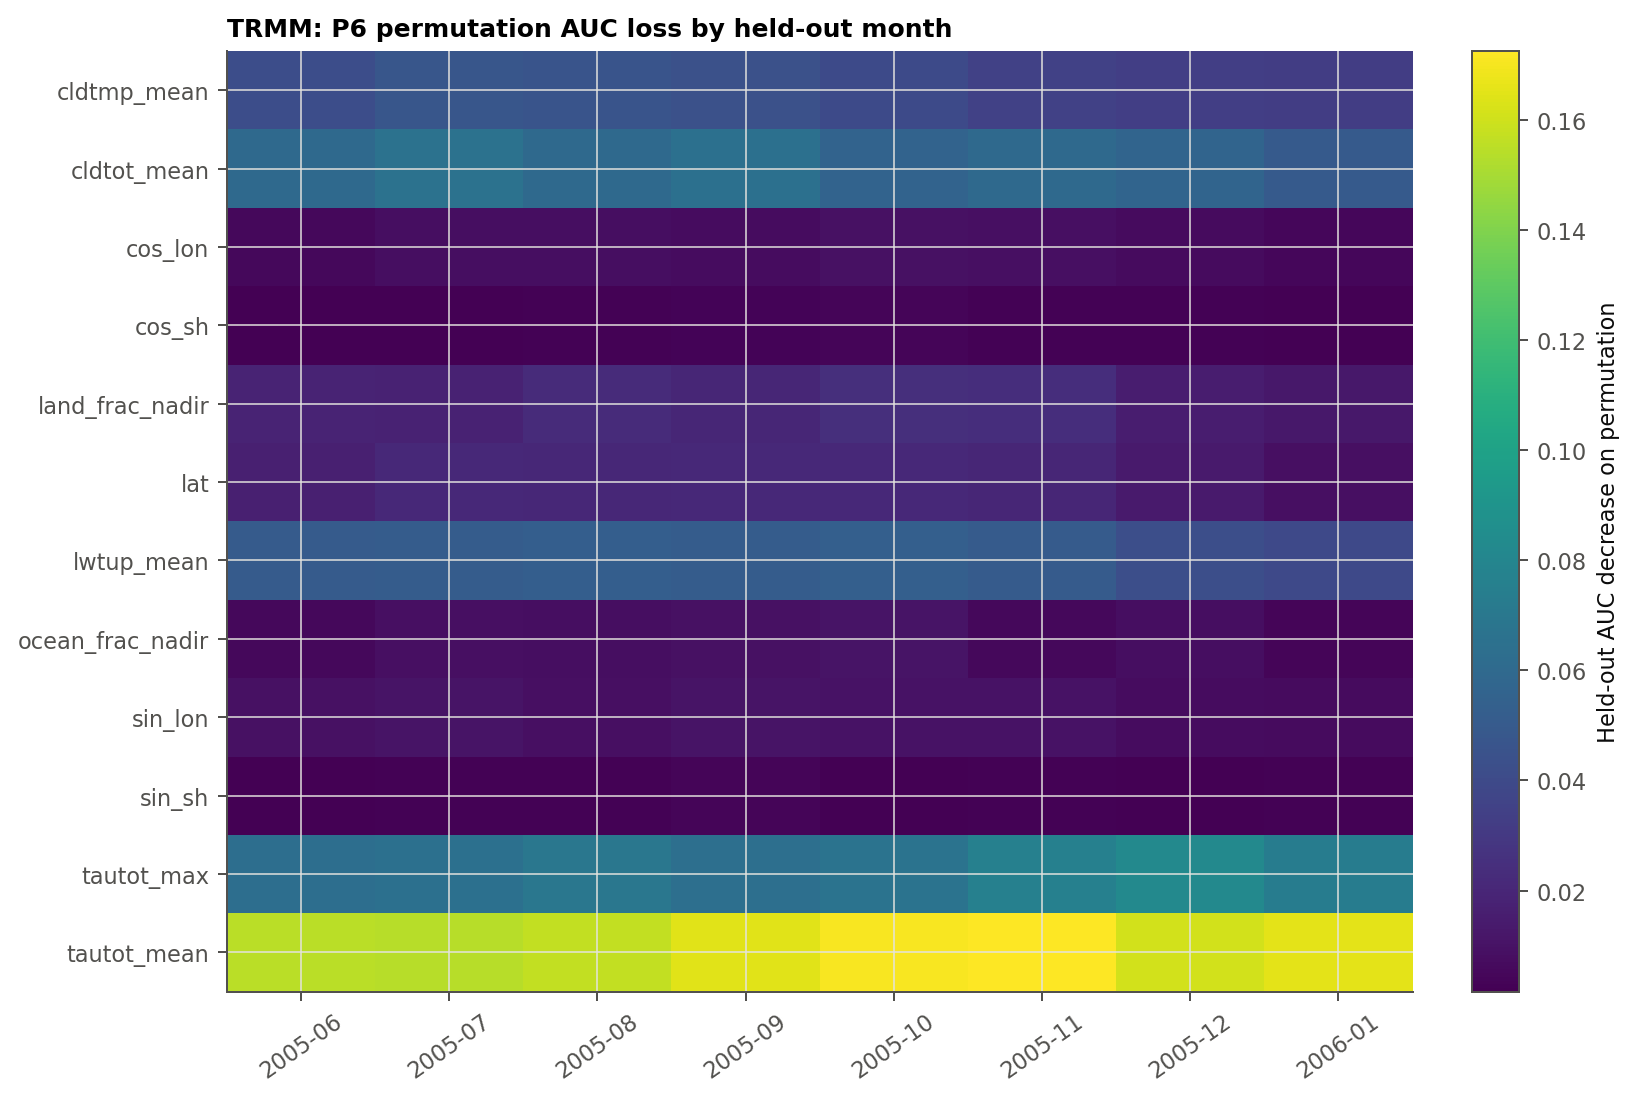

In [4]:
for experiment in ['e10_bootstrap','e10_bootstrap_summary','e11_permutation_importance','e11_permutation_importance_summary','e11_single_feature_auc']:
    display(Markdown('### ' + experiment))
    table = season_read(experiment)
    with pd.option_context('display.max_rows', None):
        display(table.drop(columns=['dataset_hash','train_months','buffer_steps'], errors='ignore').round(4))
display(Image(filename=str(SEASON_FIG / 'monthly_feature_importance.png')))


---
# Historical evaluation: Chronological future-season stress test (E1–E11)

## How to read the results

**The task.** For each minute in the **test period (Nov 2005 – Jan 2006)**, a policy gives a
score. The radar is switched on for the highest-scoring minutes, up to a power budget.

**Key terms**

| term | meaning |
|---|---|
| **duty cycle *d*** | share of minutes the radar is on (the power budget). 20% = on for 1 minute in 5. |
| **capture@d** | share of rainy minutes (≥ 1 mm/hr in the PR swath) that fall in the radar-on minutes. The main metric. Random gets *d*. |
| **mass-capture@d** | share of the total *amount* of rain in radar-on minutes (heavy rain counts more). |
| **AUC** | how well the score ranks rainy above dry minutes overall (0.5 = random, 1 = perfect). |
| **AP** | average precision; like AUC but focused on the rainy minutes (random = the rain rate). |

**The policies** (fixed rules, no learning after deployment)

| policy | what it uses |
|---|---|
| P1 random | nothing: switches on at random |
| P2 geometry LR | logistic regression on where/when only (latitude, longitude, solar hour, land/water) |
| P3 latitude band | the training rain rate of the current 5° latitude band |
| P4 single threshold | one passive feature: optical depth by day, cloud-top temperature by night |
| P5 logistic regression | linear model on all passive features + geometry (Tier A) |
| P6 gradient boosting | LightGBM on the same features: non-linear, the strongest baseline |
| P7 MLP | small neural network (two hidden layers of 64) on the same features |
| P8 oracle | knows the true rain: the upper bound, not achievable |

**How the numbers are made honest.** Models are trained on Jun–Sep 2005, the decision
threshold for each budget is set on Oct 2005, and everything is scored on Nov 2005 – Jan 2006.
One weather step is dropped at each boundary so no 30-minute snapshot appears on both sides.

In [7]:
r = lambda name: pd.read_csv(RES / f"{name}.csv")
pct = lambda x: f"{100 * x:.1f}%"
print(f"label: {meta['label']}  |  split: train {meta['split']['train'][0]}..{meta['split']['train'][-1]}, "
      f"val {meta['split']['val'][0]}, test {meta['split']['test'][0]}..{meta['split']['test'][-1]}")
print(f"results computed on sha256 {meta['data_sha256'][:16]}... with lightgbm {meta['lightgbm']}, "
      f"sklearn {meta['sklearn']}")

label: prectot_radar >= 0.000277778 kg m-2 s-1  |  split: train 2005-06..2005-09, val 2005-10, test 2005-11..2006-02
results computed on sha256 fab9c8c7ebbd5fa7... with lightgbm 4.7.0, sklearn 1.6.1


## Historical E3. Chronological result: how much rain does each policy catch?

The curve shows capture as the duty cycle grows. A good policy rises steeply on the left:
it catches a lot of rain while the radar is on only a small share of the time.

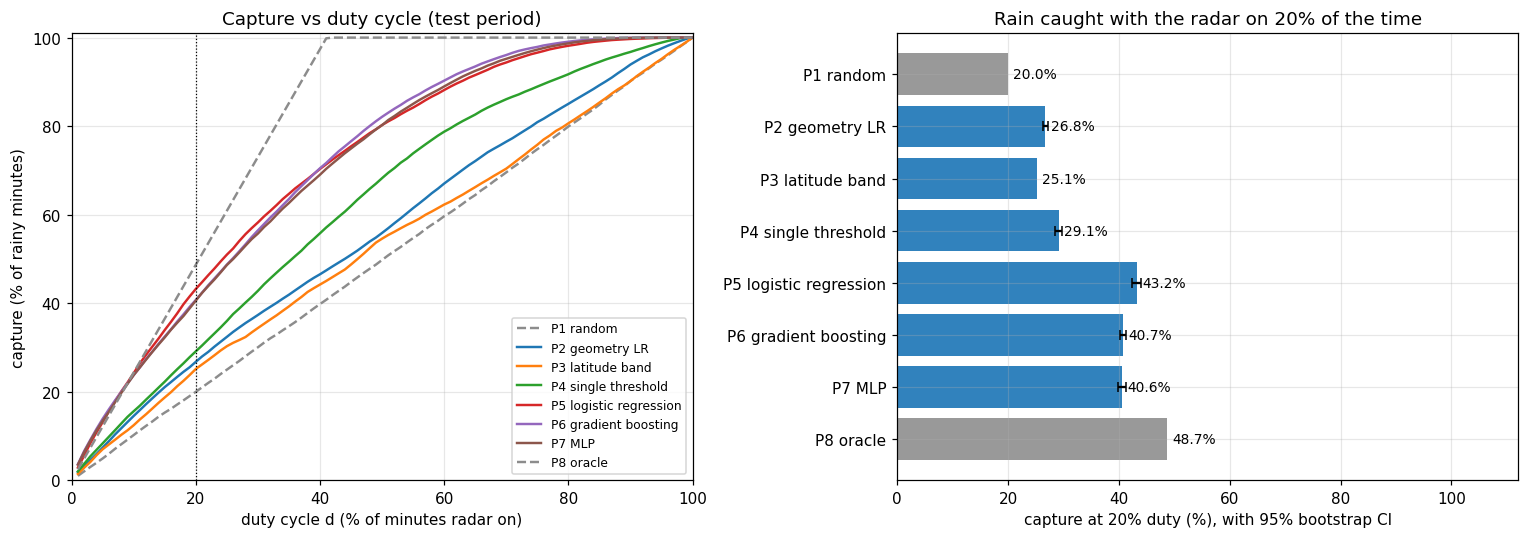

,auc,ap,capture@10%,capture@20%,capture@30%,mass_capture@20%
policy,,,,,,
P1 random,0.502,0.413,10.2%,20.0%,30.0%,19.7%
P2 geometry LR,0.593,0.498,14.5%,26.8%,37.3%,28.7%
P3 latitude band,0.542,0.461,12.4%,25.1%,34.4%,32.3%
P4 single threshold,0.704,0.584,15.6%,29.1%,42.8%,47.8%
P5 logistic regression,0.825,0.742,24.2%,43.2%,58.2%,68.6%
P6 gradient boosting,0.849,0.776,23.8%,40.7%,56.5%,64.1%
P7 MLP,0.836,0.757,23.8%,40.6%,55.7%,62.6%
P8 oracle,1.000,1.000,24.3%,48.7%,73.0%,80.9%


**Takeaway.** With the radar on 20% of the time, the best fixed policy (gradient boosting) catches **40.7%** of rainy minutes, versus 20.0% for random, 29.1% for a single-feature rule and 43.2% for logistic regression. That is **2.0x random**. The oracle shows the ceiling: at 20% duty it catches 48.7%, since 41.1% of test minutes are rainy. The small neural network (P7) reaches 40.6% with AUC 0.836, against gradient boosting's 0.849 (E10 tests whether the gap is real).

In [8]:
e3, curves, boot = r("e3_capture_table"), r("e3_capture_curves"), r("e10_bootstrap")

fig, ax = plt.subplots(1, 2, figsize=(14, 5))
for name, g in curves.groupby("policy", sort=False):
    ref = name in ("P1 random", "P8 oracle")
    ax[0].plot(100 * g.d, 100 * g.capture, "--" if ref else "-", lw=1.6,
               color="0.55" if ref else None, label=name)
ax[0].axvline(20, color="k", lw=.8, ls=":")
ax[0].set(xlabel="duty cycle d (% of minutes radar on)", ylabel="capture (% of rainy minutes)",
          xlim=(0, 100), ylim=(0, 101), title="Capture vs duty cycle (test period)")
ax[0].legend(fontsize=8)

b = boot[boot.metric == "capture@20%"].set_index("policy")
bar = e3.set_index("policy")["capture@20%"]
colors = ["0.6" if p in ("P1 random", "P8 oracle") else "#3182bd" for p in bar.index]
ax[1].barh(bar.index, 100 * bar.values, color=colors)
for p in b.index:
    ax[1].errorbar(100 * b.loc[p, "mean"], p, xerr=[[100 * (b.loc[p, "mean"] - b.loc[p, "ci_low"])],
                   [100 * (b.loc[p, "ci_high"] - b.loc[p, "mean"])]], color="k", capsize=3)
for i, v in enumerate(bar.values):
    ax[1].text(100 * v + 1, i, f"{100 * v:.1f}%", va="center", fontsize=9)
ax[1].invert_yaxis(); ax[1].set_xlim(0, 112)
ax[1].set(xlabel="capture at 20% duty (%), with 95% bootstrap CI", title="Rain caught with the radar on 20% of the time")
plt.tight_layout(); plt.show()

show = e3.set_index("policy")[["auc", "ap", "capture@10%", "capture@20%", "capture@30%", "mass_capture@20%"]]
display(show.style.format({c: "{:.3f}" for c in ["auc", "ap"]} |
                          {c: "{:.1%}" for c in show.columns if "capture" in c}))

p6, p5, p4, p1 = (bar[k] for k in ["P6 gradient boosting", "P5 logistic regression", "P4 single threshold", "P1 random"])
oracle20 = bar["P8 oracle"]
display(Markdown(
    f"**Takeaway.** With the radar on 20% of the time, the best fixed policy (gradient boosting) "
    f"catches **{pct(p6)}** of rainy minutes, versus {pct(p1)} for random, {pct(p4)} for a "
    f"single-feature rule and {pct(p5)} for logistic regression. That is "
    f"**{p6 / p1:.1f}x random**. The oracle shows the ceiling: at 20% duty it catches {pct(oracle20)}, "
    f"since {pct(curves.base_rate.iloc[0])} of test minutes are rainy. "
    f"The small neural network (P7) reaches {pct(bar['P7 MLP'])} with AUC "
    f"{e3.set_index('policy').auc['P7 MLP']:.3f}, against gradient boosting's "
    f"{e3.set_index('policy').auc['P6 gradient boosting']:.3f} (E10 tests whether the gap is real)."))

## E10. Are the differences real? (bootstrap confidence intervals)

The test period is resampled 1,000 times **by whole days** (minutes within a day are not
independent). Non-overlapping intervals mean the ranking is not a fluke of which days were
in the test set.

Every policy is scored on the **same** resampled days, so we can also take the difference
between two policies on each resample (a *paired* comparison). That is the right test when two
policies are close: their separate intervals can overlap even when one is ahead on almost
every resample.

In [9]:
ci = boot.pivot(index="policy", columns="metric", values=["mean", "ci_low", "ci_high"])
tbl = pd.DataFrame({m: [f"{ci.loc[p, ('mean', m)]:.3f}  [{ci.loc[p, ('ci_low', m)]:.3f}, {ci.loc[p, ('ci_high', m)]:.3f}]"
                        for p in ci.index] for m in ["auc", "ap", "capture@13%", "capture@20%"]}, index=ci.index)
display(tbl)
order = ["P2 geometry LR", "P4 single threshold", "P5 logistic regression", "P6 gradient boosting"]
overlap = [(a, b_) for a, b_ in zip(order, order[1:])
           if ci.loc[a, ("ci_high", "capture@20%")] >= ci.loc[b_, ("ci_low", "capture@20%")]]
display(Markdown("**Ladder.** " + ("Every step up the ladder (geometry → single feature → linear → "
        "boosting) has non-overlapping 95% intervals for capture@20%: each step is a real improvement."
        if not overlap else f"Overlapping intervals: {overlap}.")))

paired = r("e10_bootstrap_paired")
best = paired.best.iloc[0]
pt = paired.assign(**{"difference [95% CI]": [f"{m:+.3f}  [{lo:+.3f}, {hi:+.3f}]" for m, lo, hi in
                                              zip(paired.mean_diff, paired.ci_low, paired.ci_high)]})
display(Markdown(f"**Paired differences: {best} minus each other policy**"))
display(pt.pivot(index="other", columns="metric", values="difference [95% CI]")[["auc", "ap", "capture@13%", "capture@20%"]])
runner = paired.loc[paired.metric == "auc"].sort_values("mean_diff").other.iloc[0]
close = paired[paired.other == runner].set_index("metric")
real = (close.ci_low > 0) | (close.ci_high < 0)
display(Markdown(
    f"**Takeaway ({best} vs {runner}, the closest policy).** AUC difference {close.loc['auc', 'mean_diff']:+.3f} "
    f"[{close.loc['auc', 'ci_low']:+.3f}, {close.loc['auc', 'ci_high']:+.3f}], {best.split()[0]} ahead in "
    f"{100 * close.loc['auc', 'share_best_ahead']:.1f}% of resamples; capture@20% difference "
    f"{100 * close.loc['capture@20%', 'mean_diff']:+.1f} points "
    f"[{100 * close.loc['capture@20%', 'ci_low']:+.1f}, {100 * close.loc['capture@20%', 'ci_high']:+.1f}]. "
    + (f"The interval excludes zero for {', '.join(real[real].index)}."
       if real.any() else "Every interval includes zero: the two are statistically tied.")
    + (f" Not significant for {', '.join(real[~real].index)}." if real.any() and (~real).any() else "")))

,auc,ap,capture@13%,capture@20%
policy,,,,
P2 geometry LR,"0.593 [0.589, 0.597]","0.498 [0.491, 0.504]","0.185 [0.180, 0.190]","0.267 [0.263, 0.272]"
P4 single threshold,"0.704 [0.695, 0.711]","0.584 [0.573, 0.595]","0.196 [0.191, 0.201]","0.291 [0.286, 0.297]"
P5 logistic regression,"0.825 [0.820, 0.828]","0.742 [0.736, 0.748]","0.302 [0.294, 0.310]","0.432 [0.424, 0.440]"
P6 gradient boosting,"0.849 [0.846, 0.853]","0.776 [0.771, 0.782]","0.291 [0.285, 0.296]","0.407 [0.402, 0.413]"
P7 MLP,"0.836 [0.833, 0.840]","0.757 [0.751, 0.763]","0.290 [0.283, 0.297]","0.406 [0.399, 0.413]"


**Ladder.** Overlapping intervals: [('P5 logistic regression', 'P6 gradient boosting')].

**Paired differences: P6 gradient boosting minus each other policy**

metric,auc,ap,capture@13%,capture@20%
other,,,,
P2 geometry LR,"+0.257 [+0.252, +0.261]","+0.279 [+0.271, +0.286]","+0.105 [+0.098, +0.113]","+0.140 [+0.133, +0.147]"
P4 single threshold,"+0.146 [+0.138, +0.155]","+0.193 [+0.182, +0.203]","+0.095 [+0.089, +0.100]","+0.116 [+0.110, +0.122]"
P5 logistic regression,"+0.025 [+0.022, +0.027]","+0.035 [+0.030, +0.039]","-0.011 [-0.017, -0.006]","-0.025 [-0.030, -0.020]"
P7 MLP,"+0.013 [+0.012, +0.014]","+0.019 [+0.016, +0.022]","+0.000 [-0.004, +0.004]","+0.002 [-0.003, +0.006]"


**Takeaway (P6 gradient boosting vs P7 MLP, the closest policy).** AUC difference +0.013 [+0.012, +0.014], P6 ahead in 100.0% of resamples; capture@20% difference +0.2 points [-0.3, +0.6]. The interval excludes zero for auc, ap. Not significant for capture@13%, capture@20%.

## E1. Why the split matters: random rows vs a time-blocked split

A random split puts neighbouring minutes, which share the same 30-minute weather snapshot,
on both sides of train/test. That leaks information and can flatter the model.

In [10]:
e1 = r("e1_split").set_index("split")
display(e1[["n_train", "n_test", "duty", "capture", "mass_capture", "precision", "lift", "auc", "ap"]].round(3))
rb, tb = e1.loc["random 30%"], e1.loc["time-blocked"]
display(Markdown(
    f"**Takeaway.** Logistic regression at 13% duty: AUC {rb.auc:.3f} (random split) vs {tb.auc:.3f} "
    f"(time-blocked); capture {pct(rb.capture)} vs {pct(tb.capture)}. The paper reports the "
    "chronological numbers to study future-season transfer; seasonal LOMO above studies robustness across months."))

,n_train,n_test,duty,capture,mass_capture,precision,lift,auc,ap
split,,,,,,,,,
random 30%,211855,105819,0.131,0.256,0.478,0.818,1.956,0.815,0.730
time-blocked,174750,133350,0.150,0.302,0.538,0.827,2.014,0.825,0.742


**Takeaway.** Logistic regression at 13% duty: AUC 0.815 (random split) vs 0.825 (time-blocked); capture 25.6% vs 30.2%. The paper reports the chronological numbers to study future-season transfer; seasonal LOMO above studies robustness across months.

## Legacy E2: original P5–P7 seasonal table (retained for reproduction)

Each month is held out in turn, and each learned policy (P5–P7) is trained on all the others,
with a buffer at the month's edges (Feb 2006 has only one day, so it is merged into January).
The chronological stress test trains on Jun–Sep only and tests on Nov–Jan, which crosses a season. Comparing the
two on the same winter months shows how much that costs each model (dashed line = trained Jun–Sep
only).

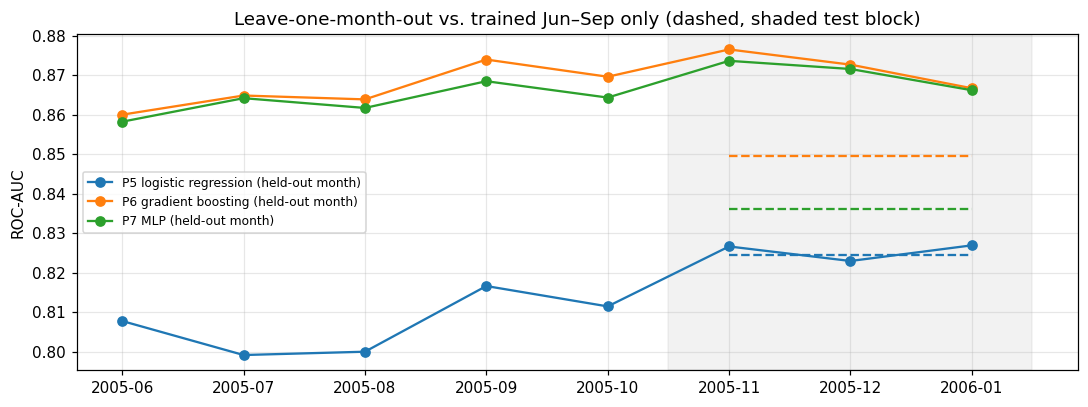

policy,P5 logistic regression,P6 gradient boosting,P7 MLP
held_out,,,
2005-06,0.808,0.860,0.858
2005-07,0.799,0.865,0.864
2005-08,0.800,0.864,0.862
2005-09,0.817,0.874,0.868
2005-10,0.812,0.870,0.864
2005-11,0.827,0.876,0.874
2005-12,0.823,0.873,0.872
2006-01,0.827,0.867,0.866


,AUC trained Jun–Sep,AUC trained on other 7 months,AP trained Jun–Sep,AP trained on other 7 months,AUC gain
policy,,,,,
P5 logistic regression,0.825,0.826,0.742,0.741,0.001
P6 gradient boosting,0.849,0.872,0.776,0.809,0.023
P7 MLP,0.836,0.870,0.757,0.808,0.034


**Takeaway.** Putting the other winter months into training raises Nov–Jan AUC by +0.001 (P5), +0.023 (P6), +0.034 (P7). This is not an isolated seasonal penalty: those folds also train on 7 months instead of 4. The ranking of the policies is the same in every held-out month, so the chronological and seasonal evaluations still answer different questions.

In [11]:
e2 = r("e2_leave_one_month_out")
blocked = r("e3_capture_table").set_index("policy")
months = list(dict.fromkeys(e2.held_out))
winter = [mo for mo in months if mo >= meta["split"]["test"][0]]
fig, ax = plt.subplots(figsize=(10, 3.8))
for p, g in e2.groupby("policy", sort=False):
    line, = ax.plot(g.held_out, g.auc, marker="o", label=f"{p} (held-out month)")
    ax.hlines(blocked.loc[p, "auc"], winter[0], winter[-1], color=line.get_color(), ls="--")
ax.axvspan(months.index(winter[0]) - 0.5, months.index(winter[-1]) + 0.5, color="0.5", alpha=0.1)
ax.set(ylabel="ROC-AUC", title="Leave-one-month-out vs. trained Jun–Sep only (dashed, shaded test block)")
ax.legend(fontsize=8); plt.tight_layout(); plt.show()
display(e2.pivot(index="held_out", columns="policy", values="auc").round(3))
w = e2[e2.held_out.isin(winter)].groupby("policy", sort=False)[["auc", "ap"]].mean()
season = pd.DataFrame({"AUC trained Jun–Sep": blocked.loc[w.index, "auc"],
                       "AUC trained on other 7 months": w.auc,
                       "AP trained Jun–Sep": blocked.loc[w.index, "ap"],
                       "AP trained on other 7 months": w.ap})
season["AUC gain"] = season.iloc[:, 1] - season.iloc[:, 0]
display(season.round(3))
rank = e2.pivot(index="held_out", columns="policy", values="auc")
same = (rank.rank(axis=1).nunique() == 1).all()
display(Markdown(
    f"**Takeaway.** Putting the other winter months into training raises Nov–Jan AUC by "
    + ", ".join(f"{g:+.3f} ({p.split()[0]})" for p, g in season['AUC gain'].items())
    + ". This is not an isolated seasonal penalty: those folds also train on 7 months "
    "instead of 4. " + ("The ranking of the policies is the same in every held-out month, so the "
    "chronological and seasonal evaluations still answer different questions." if same else "The ranking changes in some months.")))

## E4. Label geometry: which footprint defines "rain"?

Train on one definition of "rain" and score on another, for total precipitation and for
convective precipitation (the heavy, storm-type part). The PR measures a 247 km swath inside the 833 km VIRS swath, so a policy credited with VIRS-swath rain is credited with rain the radar never scans. The nadir line shows how a nadir-only radar on the same orbit would score. **Precision** is the share of
radar-on minutes that contain rain under that label.

In [12]:
e4 = r("e4_label_geometry")
e4m = meta["e4"]
for var, name in [("prectot", "total precipitation"), ("preccon", "convective precipitation")]:
    g = e4[e4.variable == var]
    tbl = pd.DataFrame({
        m: g.pivot(index="trained_on", columns="scored_on", values=m).stack()
        for m in ["capture@20%", "precision@20%", "auc"]})
    display(Markdown(f"**{name.capitalize()}** (rows: trained on → scored on)"))
    display(tbl.style.format({"capture@20%": "{:.1%}", "precision@20%": "{:.1%}", "auc": "{:.3f}"}))

def cell(var, train, score, m):
    g = e4[(e4.variable == var) & (e4.trained_on == f"{var}_{train}") & (e4.scored_on == f"{var}_{score}")]
    return g[m].iloc[0]

pr, own = e4m["positive_rate"], GEOMS[0]
text = []
for var, name in [("prectot", "Total"), ("preccon", "Convective")]:
    text.append(
        f"{name} precipitation occurs in {pct(pr[f'{var}_{own}'])} of test minutes {WHERE[own]} but "
        f"{pct(pr[f'{var}_swath'])} {WHERE['swath']}; {pct(e4m['swath_pos_label_neg_share'][var])} of "
        f"swath-rainy minutes have none {WHERE[own]}, and scoring on the swath label moves precision from "
        f"{pct(cell(var, own, own, 'precision@20%'))} to {pct(cell(var, own, 'swath', 'precision@20%'))} "
        f"and capture from {pct(cell(var, own, own, 'capture@20%'))} to "
        f"{pct(cell(var, own, 'swath', 'capture@20%'))}.")
for g in GEOMS[2:]:
    text.append(f"A {g}-only radar on this orbit would find total precipitation in "
                f"{pct(pr[f'prectot_{g}'])} of minutes, against {pct(pr[f'prectot_{own}'])} {WHERE[own]}.")
display(Markdown("**Takeaway.** " + " ".join(text) + " Headline numbers must use the radar's own footprint."))

**Total precipitation** (rows: trained on → scored on)

**Convective precipitation** (rows: trained on → scored on)

**Takeaway.** Total precipitation occurs in 41.1% of test minutes in the PR swath but 63.1% in the passive swath; 34.9% of swath-rainy minutes have none in the PR swath, and scoring on the swath label moves precision from 80.4% to 96.4% and capture from 40.7% to 31.8%. Convective precipitation occurs in 11.9% of test minutes in the PR swath but 23.8% in the passive swath; 50.1% of swath-rainy minutes have none in the PR swath, and scoring on the swath label moves precision from 43.1% to 73.2% and capture from 73.3% to 62.1%. A nadir-only radar on this orbit would find total precipitation in 15.0% of minutes, against 41.1% in the PR swath. Headline numbers must use the radar's own footprint.

## E5. Day vs night: what do we lose without sunlight?

Optical depth (`tautot`) needs reflected sunlight, so at night VIRS has only its thermal channels. Tiers remove features step by step:

| tier | features |
|---|---|
| A | everything (cloud fraction, cloud-top temperature, optical depth, longwave, geometry) |
| A_notau | A without optical depth (what is available at night) |
| B | thermal only: cloud-top temperature and longwave, plus geometry |
| C | geometry only |

"Switched" uses the tier's day model by day and its no-optical-depth version at night,
which is how a real policy would run.

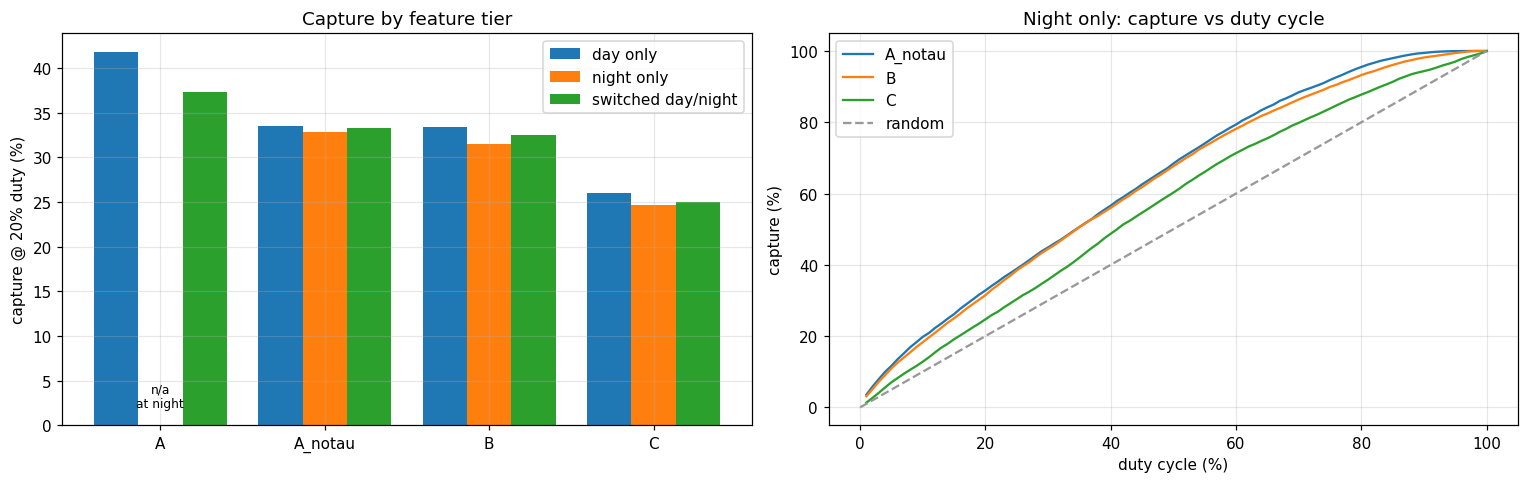

,day_capture@20%,night_capture@20%,switched_capture@20%,retention_vs_A
tier,,,,
A,0.418,n/a (no optical depth at night),0.373,1.000
A_notau,0.336,0.328,0.333,0.893
B,0.333,0.315,0.325,0.871
C,0.261,0.247,0.250,0.671


**Takeaway.** Running day/night switched, dropping optical depth keeps **89.3%** of Tier A's capture, and thermal-only (B) keeps 87.1%. Geometry alone (C) keeps 67.1%. At night the best tiers catch 32.8% at 20% duty, vs 41.8% by day with optical depth.

In [13]:
e5, night = r("e5_tiers"), r("e5_night_curves")
fig, ax = plt.subplots(1, 2, figsize=(14, 4.5))
x = np.arange(len(e5)); w = 0.27
for i, (c, lb) in enumerate([("day_capture@20%", "day only"), ("night_capture@20%", "night only"),
                             ("switched_capture@20%", "switched day/night")]):
    ax[0].bar(x + (i - 1) * w, 100 * e5[c], w, label=lb)
ax[0].set(xticks=x, xticklabels=e5.tier, ylabel="capture @ 20% duty (%)", title="Capture by feature tier")
for i in np.flatnonzero(e5["night_capture@20%"].isna()):
    ax[0].text(x[i], 2, "n/a\nat night", ha="center", fontsize=8)
ax[0].legend()
for name, g in night.groupby("tier", sort=False):
    ax[1].plot(100 * g.d, 100 * g.capture, label=name)
ax[1].plot([0, 100], [0, 100], "--", color="0.6", label="random")
ax[1].set(xlabel="duty cycle (%)", ylabel="capture (%)", title="Night only: capture vs duty cycle")
ax[1].legend(); plt.tight_layout(); plt.show()
display(e5.set_index("tier").style.format("{:.3f}", na_rep="n/a (no optical depth at night)"))
t = e5.set_index("tier")
display(Markdown(
    f"**Takeaway.** Running day/night switched, dropping optical depth keeps "
    f"**{pct(t.loc['A_notau', 'retention_vs_A'])}** of Tier A's capture, and thermal-only (B) keeps "
    f"{pct(t.loc['B', 'retention_vs_A'])}. Geometry alone (C) keeps {pct(t.loc['C', 'retention_vs_A'])}. "
    f"At night the best tiers catch {pct(t['night_capture@20%'].max())} at 20% duty, vs "
    f"{pct(t.loc['A', 'day_capture@20%'])} by day with optical depth."))

## E6. Where does the policy work best?

One global threshold (set for 20% duty overall) applied to each latitude band and surface type.
"Duty" shows how much of the budget each stratum ends up using.

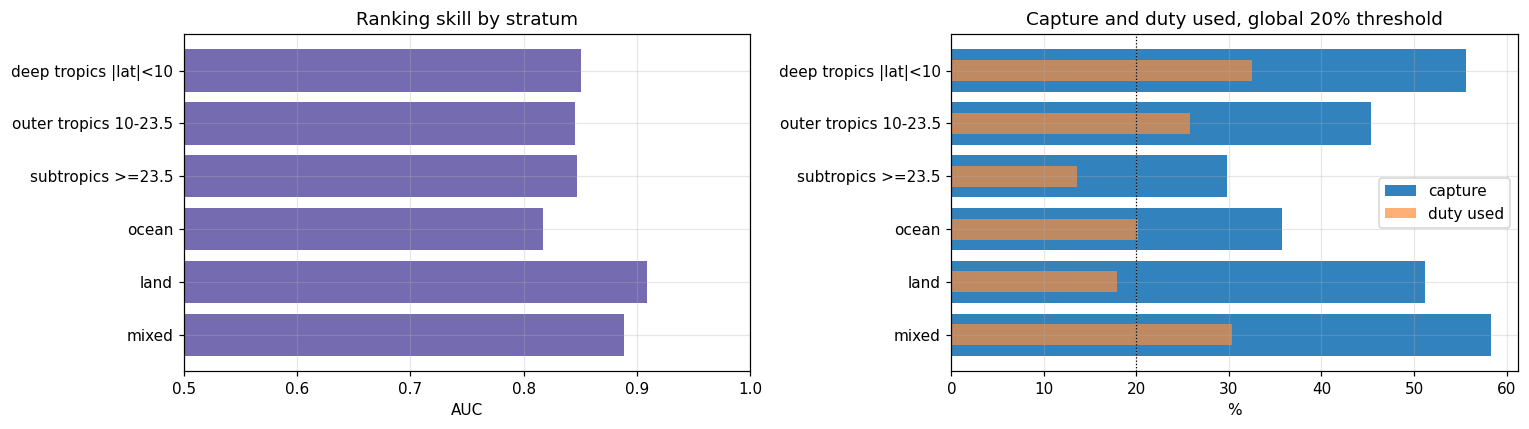

,n,base_rate,auc,duty,capture@20%
stratum,,,,,
deep tropics |lat|<10,25937,0.489,0.851,0.325,0.556
outer tropics 10-23.5,38870,0.449,0.845,0.258,0.453
subtropics >=23.5,68543,0.359,0.847,0.136,0.298
ocean,89835,0.446,0.817,0.201,0.357
land,28288,0.284,0.909,0.179,0.511
mixed,15227,0.440,0.888,0.303,0.583


**Takeaway.** Ranking is strongest for **land** (AUC 0.909, rain in 28.4% of minutes) and weakest for **ocean** (0.817, 44.6%). The rainiest band, deep tropics |lat|<10, uses 32.5% duty under the global threshold against 13.6% in subtropics >=23.5: a single threshold spends the budget where rain is most frequent.

In [14]:
e6 = r("e6_strata").set_index("stratum")
fig, ax = plt.subplots(1, 2, figsize=(14, 4))
ax[0].barh(e6.index, e6.auc, color="#756bb1"); ax[0].set(xlim=(0.5, 1), xlabel="AUC", title="Ranking skill by stratum")
ax[1].barh(e6.index, 100 * e6["capture@20%"], color="#3182bd", label="capture")
ax[1].barh(e6.index, 100 * e6.duty, color="#fd8d3c", alpha=.7, height=.4, label="duty used")
ax[1].axvline(20, color="k", ls=":", lw=.8)
ax[1].set(xlabel="%", title="Capture and duty used, global 20% threshold"); ax[1].legend()
for a in ax: a.invert_yaxis()
plt.tight_layout(); plt.show()
display(e6.round(3))
bands = e6.drop(index=["ocean", "land", "mixed"])
hi, lo = e6.auc.idxmax(), e6.auc.idxmin()
wet, dry = bands.base_rate.idxmax(), bands.base_rate.idxmin()
display(Markdown(
    f"**Takeaway.** Ranking is strongest for **{hi}** (AUC {e6.loc[hi, 'auc']:.3f}, rain in "
    f"{pct(e6.loc[hi, 'base_rate'])} of minutes) and weakest for **{lo}** ({e6.loc[lo, 'auc']:.3f}, "
    f"{pct(e6.loc[lo, 'base_rate'])}). The rainiest band, {wet}, uses {pct(e6.loc[wet, 'duty'])} duty under "
    f"the global threshold against {pct(e6.loc[dry, 'duty'])} in {dry}: a single threshold spends the "
    "budget where rain is most frequent."))

## E7. Does the conclusion depend on the rain threshold?

In [15]:
e7 = r("e7_label_sensitivity")
piv = e7.pivot(index="label", columns="model", values=["base_rate_test", "auc", "ap", "capture@d=base_rate"])
display(piv.round(3))
lg = e7[e7.model == "lgbm"].set_index("label")
lr = e7[e7.model == "lr"].set_index("label")
wins = int((lg.auc > lr.auc.reindex(lg.index)).sum())
heavy, conv = f"{LABEL} >= 5 mm/hr", f"{CONV} >= 1 mm/hr"
display(Markdown(
    "Here the duty cycle is set equal to each label's rain rate, so a perfect policy would catch 100%. "
    f"**Takeaway.** Gradient boosting beats logistic regression in AUC on {wins} of {len(lr)} labels "
    f"(boosting AUC {lg.auc.min():.3f}–{lg.auc.max():.3f}). The rarer labels (≥ 5 mm/hr: "
    f"{pct(lg.loc[heavy, 'base_rate_test'])} of minutes; convective ≥ 1 mm/hr: "
    f"{pct(lg.loc[conv, 'base_rate_test'])}) reach AP {lg.loc[heavy, 'ap']:.3f} and {lg.loc[conv, 'ap']:.3f}, "
    f"and a budget equal to their rarity catches {pct(lg.loc[heavy, 'capture@d=base_rate'])} and "
    f"{pct(lg.loc[conv, 'capture@d=base_rate'])} of them."))

base_rate_test           auc            ap        capture@d=base_rate       
model                                                 lgbm     lr   lgbm     lr   lgbm     lr                lgbm     lr
label                                                                                                                   
preccon_radar >= 1 mm/hr                             0.119  0.119  0.904  0.890  0.547  0.479               0.526  0.480
prectot_radar > train median (median split)          0.480  0.480  0.861  0.838  0.833  0.804               0.790  0.779
prectot_radar >= 0.1 mm/hr                           0.739  0.739  0.932  0.912  0.973  0.964               0.925  0.919
prectot_radar >= 1 mm/hr                             0.411  0.411  0.849  0.825  0.776  0.742               0.737  0.729
prectot_radar >= 5 mm/hr                             0.219  0.219  0.857  0.835  0.605  0.579               0.593  0.591

Here the duty cycle is set equal to each label's rain rate, so a perfect policy would catch 100%. **Takeaway.** Gradient boosting beats logistic regression in AUC on 5 of 5 labels (boosting AUC 0.849–0.932). The rarer labels (≥ 5 mm/hr: 21.9% of minutes; convective ≥ 1 mm/hr: 11.9%) reach AP 0.605 and 0.547, and a budget equal to their rarity catches 59.3% and 52.6% of them.

## E8. Missing data and E9. Policy cost

In [16]:
display(r("e8_missing_data").fillna("").set_index("item"))
e9 = r("e9_policy_cost").set_index("policy")
display(e9)
gaps = {c: n for c, n in report["nan_counts"].items() if not c.endswith("_valid")}
display(Markdown(
    f"**Takeaway.** Invalid targets: {sum(report['invalid_targets'].values())}. Missing feature values "
    f"({', '.join(f'{c}: {n:,}' for c, n in gaps.items())}) are handled by imputation or natively by "
    f"LightGBM. On cost: logistic regression is {int(e9.loc['P5 logistic regression', 'parameters'])} "
    f"parameters (~{e9.loc['P5 logistic regression', 'serialized_bytes'] / 1e3:.0f} kB), while gradient "
    f"boosting is {int(e9.loc['P6 gradient boosting', 'parameters']):,} parameters "
    f"(~{e9.loc['P6 gradient boosting', 'serialized_bytes'] / 1e6:.1f} MB). All learned policies take "
    f"{e9.wall_ms_per_decision_python.min():.1f}–{e9.wall_ms_per_decision_python.max():.1f} ms per decision in "
    "Python on a laptop (mostly call overhead; it varies between runs), against a 60 s decision interval."))

,count,note
item,,
rows in dataset,352800.0,
rows with invalid prectot_radar,0.0,
rows with invalid prectot_swath,0.0,
rows with any NaN Tier A feature,6598.0,
NaN in cldtmp_mean,6598.0,
train rows used (valid label),174750.0,
val rows used (valid label),44580.0,
test rows used (valid label),133350.0,
drop rows used (valid label),120.0,


,inputs,parameters,operations,serialized_bytes,wall_ms_per_decision_python
policy,,,,,
P2 geometry LR,7,8,~7 multiply-adds + 1 sigmoid,2772,0.773846
P5 logistic regression,12,14,~13 multiply-adds + 1 sigmoid,3168,0.784626
P6 gradient boosting,12,18300,"~3192 comparisons (300 trees, mean depth 10.6)",1053943,0.557602
P7 MLP,12,5121,~4992 multiply-adds,131386,0.816224


**Takeaway.** Invalid targets: 0. Missing feature values (cldtmp_mean: 6,598) are handled by imputation or natively by LightGBM. On cost: logistic regression is 14 parameters (~3 kB), while gradient boosting is 18,300 parameters (~1.1 MB). All learned policies take 0.6–0.8 ms per decision in Python on a laptop (mostly call overhead; it varies between runs), against a 60 s decision interval.

## E11. Which passive features matter?

Two views. **Permutation importance**: shuffle one feature and see how much the best model's
AUC drops. **Single-feature AUC**: how well each feature ranks rain on its own.

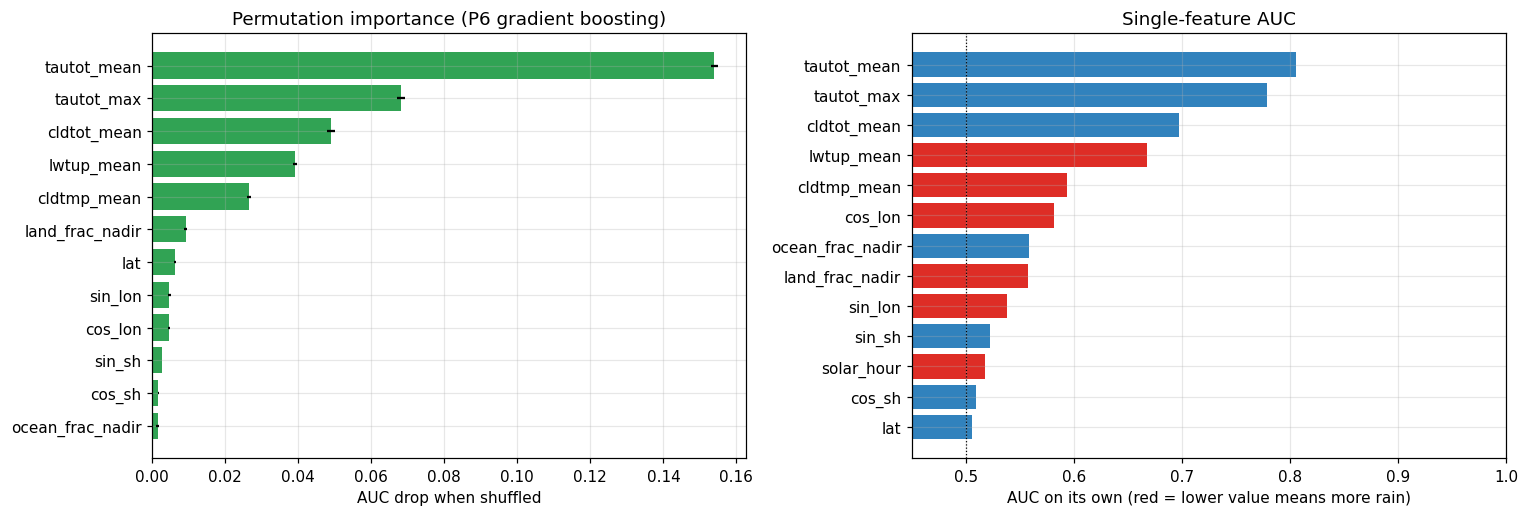

**Takeaway.** The model leans most on **tautot_mean** and **tautot_max**, then cldtot_mean and lwtup_mean. The best single feature, `tautot_mean`, reaches AUC 0.806 on its own, against 0.825 for logistic regression and 0.849 for gradient boosting on all features.

In [17]:
e3i_auc = e3.set_index("policy").auc
perm = r("e11_permutation_importance").sort_values("auc_drop_mean")
single = r("e11_single_feature_auc").sort_values("auc")
fig, ax = plt.subplots(1, 2, figsize=(14, 4.8))
ax[0].barh(perm.feature, perm.auc_drop_mean, xerr=perm.auc_drop_std, color="#31a354")
ax[0].set(xlabel="AUC drop when shuffled", title=f"Permutation importance ({meta['e11_best_policy']})")
ax[1].barh(single.feature, single.auc, color=["#de2d26" if i else "#3182bd" for i in single.inverted])
ax[1].axvline(0.5, color="k", ls=":", lw=.8)
ax[1].set(xlim=(0.45, 1), xlabel="AUC on its own (red = lower value means more rain)",
          title="Single-feature AUC")
plt.tight_layout(); plt.show()
top = perm.sort_values("auc_drop_mean", ascending=False).feature.tolist()
display(Markdown(
    f"**Takeaway.** The model leans most on **{top[0]}** and **{top[1]}**, then {top[2]} and {top[3]}. "
    f"The best single feature, `{single.feature.iloc[-1]}`, reaches AUC {single.auc.iloc[-1]:.3f} on its "
    f"own, against {e3i_auc['P5 logistic regression']:.3f} for logistic regression and "
    f"{e3i_auc['P6 gradient boosting']:.3f} for gradient boosting on all features."))

## Cesium CZML export

Writes the orbit simulation for Cesium into `cesium/`: one CZML per 30-day window at full
one-minute detail, plus a downsampled full-run file. The satellite is re-propagated from the
same TLE set as the extraction. Ground markers are green when precipitation in the PR swath is
≥ 1 mm/hr (PR on), red when it is below, and grey when there is no valid decision. A beam is
drawn while the PR fires. Drag any file onto a Cesium viewer, for example
[Cesium Sandcastle](https://sandcastle.cesium.com), to play it.

In [18]:
sys.path.insert(0, str(ROOT / "task_outputs"))
import export_trackwise as E                           # same exporter as the command-line script

E.export_czml(E.add_fire(pd.read_parquet(DATA), M), M)
print(f"CZML files in {E.czml_dir(M).relative_to(ROOT)}/")

CZML colour: radar precip >= 1 mm/hr (41.6% green; training label fire is 50.0% positive)


CZML month: TRMM_trackwise_decisions_month01_20050601-20050701.czml (43,200 decisions, 18,950 firings, 19.8 MB)


CZML month: TRMM_trackwise_decisions_month02_20050701-20050731.czml (43,200 decisions, 19,326 firings, 19.8 MB)


CZML month: TRMM_trackwise_decisions_month03_20050731-20050830.czml (43,200 decisions, 18,142 firings, 19.8 MB)


CZML month: TRMM_trackwise_decisions_month04_20050830-20050929.czml (43,200 decisions, 17,126 firings, 19.8 MB)


CZML month: TRMM_trackwise_decisions_month05_20050929-20051029.czml (43,200 decisions, 17,051 firings, 19.8 MB)


CZML month: TRMM_trackwise_decisions_month06_20051029-20051128.czml (43,200 decisions, 17,208 firings, 19.8 MB)


CZML month: TRMM_trackwise_decisions_month07_20051128-20051228.czml (43,200 decisions, 18,149 firings, 19.8 MB)


CZML month: TRMM_trackwise_decisions_month08_20051228-20060127.czml (43,200 decisions, 17,766 firings, 19.8 MB)
CZML month: TRMM_trackwise_decisions_month09_20060127-20060201.czml (7,200 decisions, 3,058 firings, 3.3 MB)


CZML full:  TRMM_trackwise_decisions_full_downsampled.czml (70,560 track samples, 20,753 markers, 8,555 firing, 10.6 MB)
CZML files in missions/trmm/cesium/


## Historical chronological summary

In [19]:
e3i = e3.set_index("policy")
e2b = e2[e2.policy == "P6 gradient boosting"]
summary = pd.DataFrame({
    "value": [f"{len(rows):,} one-minute decisions, G5NR weather 2005-06-01 .. 2006-02-01",
              pct(curves.base_rate.iloc[0]),
              f"{pct(e3i.loc['P6 gradient boosting', 'capture@20%'])} (random {pct(e3i.loc['P1 random', 'capture@20%'])})",
              f"{e3i.loc['P6 gradient boosting', 'auc']:.3f}",
              f"{pct(e3i.loc['P6 gradient boosting', 'mass_capture@20%'])}",
              f"{pct(t.loc['A_notau', 'retention_vs_A'])} of full skill",
              f"{e2b.auc.min():.3f} – {e2b.auc.max():.3f}",
              ", ".join(top[:3])]},
    index=[M.title, f"rainy minutes in test (>= 1 mm/hr, {GEOMS[0]})", "best baseline capture @ 20% duty",
           "best baseline AUC", "best baseline rain-amount capture @ 20%",
           "without optical depth (night-capable)", "best baseline AUC range across held-out months",
           "most important features"])
display(summary)

,value
TRMM,"352,800 one-minute decisions, G5NR weather 200..."
"rainy minutes in test (>= 1 mm/hr, radar)",41.1%
best baseline capture @ 20% duty,40.7% (random 20.0%)
best baseline AUC,0.849
best baseline rain-amount capture @ 20%,64.1%
without optical depth (night-capable),89.3% of full skill
best baseline AUC range across held-out months,0.860 – 0.876
most important features,"tautot_mean, tautot_max, cldtot_mean"


**Historical bar for RL.** Also evaluate seasonal consistency above; these chronological numbers answer future-season transfer only: a learned gating policy
under the same 20% budget has to catch more than the gradient-boosting baseline's share of rainy
minutes on the same test period, or show that it uses the budget better (for example, by
adapting the duty cycle to the weather it sees, which a fixed threshold cannot do).

CSV exports for visualisation are produced by `task_outputs/export_trackwise.py --mission trmm`
into `exports/` (not in git); the Cesium CZML files go to `cesium/` (see the export cell above).